<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-06/lab-024-vae-cvae.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 024 <br>
<hr/>

# Lab 024 — Variational and conditional autoencoders

The images $\mathbf x_1,\dots,\mathbf x_n$ of a data set are samples from an unknown probability distribution $p(\mathbf x)$. A generative model learns an approximation $p_\theta(\mathbf x)$ of it from the samples ($\theta$ denotes all its parameters) and then draws new samples: images that are not in the data set but could have been. In physics the same task appears as learning the Boltzmann distribution of a spin model from Monte Carlo snapshots and producing new configurations at a chosen temperature, which is the subject of Lab 025. Here we develop the method on MNIST handwritten digits.

The notebook follows one line of thought, in which every step repairs what the previous one could not do. We start from the autoencoder (AE) of Lab 017, which compresses an image into a short latent vector and reconstructs it. It learns no probability distribution of the latent vectors, and decoding random latent vectors gives no digits (Section 1). To put a distribution on the latent space we need the language of likelihood and of models with hidden variables (Section 2). The variational autoencoder (VAE) supplies it: the encoder returns a Gaussian cloud of latent vectors for each image instead of a single point, a fixed prior distribution $\mathcal N(0,I)$ says where latent vectors live, and the training objective, the evidence lower bound (ELBO), pulls all clouds onto that prior so that every region of it decodes to a valid image (Section 3). A two-dimensional toy problem, whose every ingredient can be drawn, shows what the trained encoder, decoder, prior and aggregate posterior look like (Section 4). We then train VAEs on MNIST (Section 5) and look in detail at what sampling a trained VAE does: reconstruction against generation, decoder means against decoder samples, the gap between the prior and the encoded data, interpolation (Section 6). The latent coordinates of a plain VAE mix several properties of a digit, which motivates the goal of one coordinate per property, treated in Lab 026 (Section 7). A classifier trained on real digits then measures what the generator produces (Section 8), and the conditional VAE (cVAE) lets us choose what to generate by giving a label as an extra input (Section 9).

The implementation uses JAX: the networks are defined in `flax.nnx`, the optimiser comes from `optax`, each training epoch is one jit-compiled `lax.scan`, and all random numbers come from explicit keys. The figures of the Lecture 6 slides are saved to `../beamer/figures/gen_*.png`, created at the size at which they appear on the slides, and the numbers quoted there to `../beamer/figures/numbers_lab024.json`.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`; the networks and numbers of epochs are chosen so that the notebook finishes in about a quarter of an hour on a multi-core CPU. With a GPU runtime you can delete that line and train longer.
> 2. `jax`, `flax`, `optax` and `matplotlib` are pre-installed in Colab.
> 3. MNIST is read from `data/MNIST_raw/` (the four `*-ubyte.gz` files); if they are missing, the notebook downloads them.
> 4. Run the cells *in order*: later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import gzip, json, time, urllib.request
from math import comb
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, Rectangle, ConnectionPatch
from matplotlib.collections import LineCollection
from scipy.stats import norm, chi

import jax, jax.numpy as jnp
import optax
import flax
from flax import nnx

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10,
            "ytick.labelsize": 10, "legend.fontsize": 10, "lines.linewidth": 1.5, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
cmap10 = plt.get_cmap("tab10")

import os

OUT = "figures"; os.makedirs(OUT, exist_ok=True)                 # slide figures
os.makedirs(OUT, exist_ok=True)
def save(fig, name, **kw):
    """Save a slide figure; it is created at its printed size, so it is placed on the slide without scaling."""
    fig.savefig(f"{OUT}/{name}", dpi=300, bbox_inches="tight", pad_inches=0.02, **kw)

def mosaic(imgs, nrow, ncol, pad=2):
    """Images (nrow * ncol, 784) -> one array with the 28 x 28 images on a grid, white gaps of `pad` pixels."""
    big = np.zeros((nrow * (28 + pad) - pad, ncol * (28 + pad) - pad))
    for k, im in enumerate(np.asarray(imgs)[: nrow * ncol]):
        r, c = divmod(k, ncol)
        big[r * (28 + pad):r * (28 + pad) + 28, c * (28 + pad):c * (28 + pad) + 28] = np.asarray(im).reshape(28, 28)
    return big

def show_grid(imgs, nrow, ncol, name=None, width=5.5, row_labels=None, label_width=0.0, title=None):
    """Images (n, 784) as an nrow x ncol grid, `width` inches wide (slide size), with optional row labels
    in a margin of `label_width` inches on the left. Grey level = pixel value (0 white, 1 black)."""
    cell = (width - label_width) / ncol
    with mpl.rc_context(SLIDE_RC):
        fig = plt.figure(figsize=(width, cell * nrow + (0.25 if title else 0)))
        ax = fig.add_axes([label_width / width, 0, 1 - label_width / width, cell * nrow / fig.get_figheight()])
        ax.imshow(mosaic(imgs, nrow, ncol), cmap="gray_r", vmin=0, vmax=1, extent=(0, ncol, nrow, 0))
        ax.axis("off")
        for r, lab in enumerate(row_labels or []):
            ax.text(-0.15, r + 0.5, lab, ha="right", va="center", fontsize=11)
        if title:
            ax.set_title(title, fontsize=11)
        if name: save(fig, name)
        plt.show()

nums = {}                                 # numbers quoted on the slides
t_start = time.time()
print("JAX", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__)
print("devices:", jax.devices())

JAX 0.11.0 | flax 0.12.8 | optax 0.2.6
devices: [CpuDevice(id=0)]


<hr/>
## 0. MNIST data

MNIST (Modified National Institute of Standards and Technology database) contains $28\times28$ grayscale digits, $60\,000$ for training and $10\,000$ for testing [LeCun *et al.*, Proc. IEEE **86**, 2278 (1998), [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791)]. Each image becomes a vector $\mathbf x\in[0,1]^{784}$, one number per pixel, 0 for white and 1 for black. The files are stored in the IDX format, a short header with the array shape followed by the raw bytes, which `gzip` and `numpy` read directly.

In [2]:
MNIST_DIR = "data/MNIST_raw"
MNIST_FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
               "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
if not all(os.path.exists(f"{MNIST_DIR}/{f}") for f in MNIST_FILES):
    os.makedirs(MNIST_DIR, exist_ok=True)
    for f in MNIST_FILES:
        urllib.request.urlretrieve(f"https://storage.googleapis.com/cvdf-datasets/mnist/{f}", f"{MNIST_DIR}/{f}")

def read_idx(path):
    with gzip.open(path, "rb") as fh:
        data = fh.read()
    ndim = data[3]                                                  # 3 for images, 1 for labels
    shape = np.frombuffer(data[4:4 + 4 * ndim], dtype=">i4")        # big-endian int32 sizes
    return np.frombuffer(data[4 + 4 * ndim:], dtype=np.uint8).reshape(shape)

Xtr = read_idx(f"{MNIST_DIR}/{MNIST_FILES[0]}").reshape(-1, 784).astype(np.float32) / 255.0
ytr = read_idx(f"{MNIST_DIR}/{MNIST_FILES[1]}").astype(np.int32)
Xte = read_idx(f"{MNIST_DIR}/{MNIST_FILES[2]}").reshape(-1, 784).astype(np.float32) / 255.0
yte = read_idx(f"{MNIST_DIR}/{MNIST_FILES[3]}").astype(np.int32)
Xtr_d, ytr_d, Xte_d = jnp.asarray(Xtr), jnp.asarray(ytr), jnp.asarray(Xte)
Ctr_d = jax.nn.one_hot(ytr_d, 10)                                   # one-hot labels, used by the cVAE
print("train", Xtr.shape, "test", Xte.shape)

train (60000, 784) test (10000, 784)


### Training loop

All models of this notebook are trained by the same function, so we write it once. A model is split by `nnx.split` into its static structure (`graphdef`) and its parameters, which makes the loss a pure function of the parameters, a minibatch and a random key. `jax.value_and_grad` then returns the loss together with its gradient, `optax.adam` updates the parameters, `jax.lax.scan` runs over all minibatches of one epoch, and `jax.jit` compiles the whole epoch into one program of XLA (Accelerated Linear Algebra), the compiler behind JAX.

Each model provides `loss_fn(model, batch, key)`, which returns the loss and a dictionary of numbers to monitor. The key is split once per minibatch: every minibatch gets fresh random numbers, which the VAE needs for its sampling step, while the whole run is still fixed by one seed.

In [3]:
def train(model, loss_fn, data, epochs, seed, batch_size=128, lr=1e-3, log_every=5):
    """Adam; one jit-compiled lax.scan per epoch. data: tuple of arrays with the same first dimension."""
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.adam(lr)
    opt_state = tx.init(params)
    n = data[0].shape[0]
    n_batches = n // batch_size

    def batch_loss(params, batch, key):
        return loss_fn(nnx.merge(graphdef, params, rest), batch, key)

    @jax.jit
    def train_epoch(params, opt_state, data, key):
        k_perm, k_steps = jax.random.split(key)
        idx = jax.random.permutation(k_perm, n)[: n_batches * batch_size].reshape(n_batches, batch_size)
        keys = jax.random.split(k_steps, n_batches)
        def step(carry, inp):
            params, opt_state = carry
            batch_idx, k = inp
            batch = tuple(a[batch_idx] for a in data)
            (loss, aux), grads = jax.value_and_grad(batch_loss, has_aux=True)(params, batch, k)
            updates, opt_state = tx.update(grads, opt_state, params)
            return (optax.apply_updates(params, updates), opt_state), aux
        (params, opt_state), aux = jax.lax.scan(step, (params, opt_state), (idx, keys))
        return params, opt_state, jax.tree.map(jnp.mean, aux)

    key, history, t0 = jax.random.key(seed), [], time.time()
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, opt_state, aux = train_epoch(params, opt_state, data, sub)
        history.append({k: float(v) for k, v in aux.items()})
        if ep == 0 or (ep + 1) % log_every == 0 or ep + 1 == epochs:
            print(f"  epoch {ep + 1:3d}: " + "  ".join(f"{k} {v:.4f}" for k, v in history[-1].items())
                  + f"   ({time.time() - t0:5.1f} s)")
    nnx.update(model, params)
    return model, {k: np.array([h[k] for h in history]) for k in history[0]}

def in_chunks(fn, *arrays, chunk=2000):
    """Apply fn to chunks of the arrays and concatenate (keeps the memory small)."""
    outs = [fn(*(a[i:i + chunk] for a in arrays)) for i in range(0, arrays[0].shape[0], chunk)]
    return jax.tree.map(lambda *xs: np.concatenate([np.asarray(x) for x in xs]), *outs)

<hr/>
## 1. Autoencoder latent space

Recall Lab 017. An autoencoder (AE) consists of two networks. The encoder $E$ maps an image to a latent vector $\mathbf z=E(\mathbf x)\in\mathbb R^d$ with $d\ll784$, and the decoder $G$ maps it back to an image, $\hat{\mathbf x}=G(\mathbf z)$. Both are trained together to minimise the mean squared error (MSE) of the reconstruction,
$$\mathcal L_{\rm AE}=\frac1n\sum_{i=1}^n\frac1{784}\big\lVert\mathbf x_i-G(E(\mathbf x_i))\big\rVert^2 ,$$
the average over images and pixels of the squared difference between a pixel and its reconstruction; it is 0 for a perfect copy, and a value of 0.01 means a typical pixel error of $\sqrt{0.01}=0.1$. Since $\mathbf z$ has far fewer numbers than $\mathbf x$, the network must find a compressed description of the digits. Each training image is thereby mapped to one point of the latent space, and nothing else about the latent space is learned: the training never asks what a latent vector that no image was mapped to should decode to.

The decoder nevertheless turns *any* $\mathbf z$ into an image, so it is tempting to use it as a generator: pick a latent vector that no training image was mapped to and hope for a new digit. This section tests that idea. We train the dense autoencoder of Lab 017 ($784\to256\to64\to d$ and back, ReLU (rectified linear unit, $\max(0,u)$) in the hidden layers, a sigmoid $1/(1+e^{-u})$ at the output so that pixels lie in $(0,1)$; 12 epochs) twice: with $d=2$, so that the latent plane can be drawn, and with $d=16$. For a minibatch of $B$ images the shapes are $\mathbf x$: $(B,784)$ $\to$ $(B,256)\to(B,64)\to\mathbf z$: $(B,d)$ $\to(B,64)\to(B,256)\to\hat{\mathbf x}$: $(B,784)$.

### Network drawings

Before training we draw the networks of this notebook, all with one function, `draw_network`. It is generic: a network is described by its columns of nodes (a layer of width $n$ is one column) and by the edges between columns. A dense layer joins every node of one column to every node of the next, one line per weight; an element-wise operation, such as the sampling step of the VAE in Section 3, joins node $j$ only to node $j$. A layer of 784 nodes cannot be drawn node by node, so a column wider than `max_nodes` gets `max_nodes` circles plus `growth` circles for every doubling of its width, an ellipsis for the omitted nodes, and its true width written underneath. The height of a column thus grows with the width of the layer, logarithmically, and the autoencoder is seen to narrow to the latent layer and to widen again. All coordinates are in inches of the printed figure, so a drawing made 5.5 inches wide is placed on a slide without scaling and its 10-point labels stay 10 points high.

The second cell builds the column and edge lists for the networks of this notebook: `draw_ae` for the autoencoder, and `draw_vae` for the variational autoencoder of Section 3, with an optional condition (Section 9) and an optional prior network (used in Lab 025). `draw_vae` has two modes, the network used in training and the smaller network used for generation, and `draw_vae_pair` puts both side by side (Section 6).

In [4]:
NODE_COLOR = {"input": "#8A929E", "hidden": "#005CA7", "latent": "#D35A05", "noise": "#F2B28A",
              "cond": "#2E8B57", "output": "#002B5C", "unused": "#E3E5E8"}


def draw_network(layers, edges, size=(5.5, 2.2), max_nodes=4, growth=0.9, gap=0.14, r=0.045, fontsize=10, notes=(),
                 fig=None):
    """Nodes-and-edges drawing of a network, created at its physical size (all coordinates in inches).

    layers   : dict name -> layer. A layer is a dict with
               x, y      position of the centre of the column (inches from the lower-left corner)
               n         true width of the layer (number of nodes)
               kind      colour key of NODE_COLOR: "input", "hidden", "latent", "noise", "cond", "output"
               top, bottom (optional) text written above / below the column; the true width n is
                         written below the column unless show_n=False
               left      (optional) text written left of the column
               shown     (optional) at most this many circles (keeps side columns such as mu, eps small)
               image     (optional) a 2D array drawn as a square picture instead of a column of nodes;
                         its side is given by `side` (inches)
    edges    : list of (a, b, style): lines from every drawn node of layer a to every drawn node of layer b
               ("dense": one line per weight), or from node j to node j only ("one": an element-wise
               operation, e.g. z = mu + sigma * eps), or "dashed": element-wise, dashed (random input),
               or "arrow": one arrow from the picture or column a to column b
    size     : figure size (inches); for a slide, 5.5 in wide = the full text width, so fonts are true sizes
    max_nodes, growth : a layer of width n <= max_nodes is drawn node by node; a wider layer gets
               max_nodes + growth * log2(n / max_nodes) circles and an ellipsis, so the height of a
               column grows with the width (784 nodes: 11 circles; 16 nodes: 6 circles)
    gap, r   : vertical distance between neighbouring circles and their radius (inches)
    fontsize : font size of all labels (points, as printed)
    notes    : extra texts, tuples (x, y, text, dict of matplotlib text options)
    fig      : draw into this figure (made by an earlier call) instead of a new one, e.g. two networks side by side
    Returns the figure.
    """
    if fig is None:                                            # one axes covering the figure, 1 data unit = 1 inch
        fig = plt.figure(figsize=size)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.set_xlim(0, size[0]); ax.set_ylim(0, size[1]); ax.set_aspect("equal"); ax.axis("off")
    ax = fig.axes[0]
    ys = {}                                                    # heights of the drawn nodes of every column

    # ---- the columns: circles (or a picture), an ellipsis for the omitted nodes, labels above and below
    for name, L in layers.items():
        x, y0 = L["x"], L["y"]
        if "image" in L:                                       # a picture, e.g. the input digit
            s = L.get("side", 0.55)
            ax.imshow(L["image"], cmap=L.get("cmap", "gray_r"), extent=(x - s / 2, x + s / 2, y0 - s / 2, y0 + s / 2),
                      interpolation="nearest", zorder=2)
            ys[name], half = np.array([y0]), s / 2
        else:
            n = L["n"]
            k = n if n <= max_nodes else max_nodes + int(round(growth * np.log2(n / max_nodes)))
            k = min(k, L.get("shown", k))                     # optional cap for small side columns
            capped = k < n
            slots = k + 1 if capped else k                     # one slot for the ellipsis if nodes are omitted
            y = y0 + gap * ((slots - 1) / 2 - np.arange(slots))
            if capped:                                         # three dots in the middle slot
                mid = slots // 2
                ax.scatter([x] * 3, y[mid] + gap * np.array([-0.28, 0, 0.28]), s=1.2, color="k", zorder=3)
                y = np.delete(y, mid)
            for yi in y:
                ax.add_patch(Circle((x, yi), r, facecolor=NODE_COLOR[L["kind"]], edgecolor="k", lw=0.4, zorder=3))
            ys[name], half = y, gap * (slots - 1) / 2 + r
        below = "\n".join(t for t in [str(L["n"]) if L.get("show_n", True) and "n" in L else "", L.get("bottom", "")] if t)
        if below:
            ax.text(x, y0 - half - 0.03, below, ha="center", va="top", fontsize=fontsize, linespacing=1.0)
        if L.get("left"):
            ax.text(x - r - 0.05, y0, L["left"], ha="right", va="center", fontsize=fontsize)
        if L.get("top"):
            ax.text(x, y0 + half + 0.03, L["top"], ha="center", va="bottom", fontsize=fontsize, linespacing=1.0)

    # ---- the edges: drawn below the circles, thin and semi-transparent, so that they end at the circles
    for a, b, style in edges:
        xa, xb = layers[a]["x"], layers[b]["x"]
        if style == "arrow":
            ax.annotate("", xy=(xb - 0.08, layers[b]["y"]), xytext=(xa + layers[a].get("side", 0) / 2 + 0.03, layers[a]["y"]),
                        arrowprops=dict(arrowstyle="-|>", lw=0.8, color="k"))
            continue
        if style == "dense":
            segs = [[(xa, p), (xb, q)] for p in ys[a] for q in ys[b]]
            kw = dict(colors="0.5", alpha=0.35, linewidths=0.3)
        else:                                                  # element-wise: node j -> node j
            segs = [[(xa, p), (xb, q)] for p, q in zip(ys[a], ys[b])]
            kw = dict(colors=NODE_COLOR["latent"], alpha=0.9, linewidths=0.6,
                      linestyles="--" if style == "dashed" else "-")
        ax.add_collection(LineCollection(segs, zorder=1, **kw))

    # ---- free texts: formulas, brackets naming encoder and decoder, ...
    for x, y, text, kw in notes:
        ax.text(x, y, text, fontsize=kw.pop("fontsize", fontsize), **kw)
    return fig


def bracket(ax, x0, x1, y, text, color="k", fontsize=10):
    """A horizontal bracket from x0 to x1 at height y (inches) with a text above it, naming a block of layers."""
    ax.plot([x0, x0, x1, x1], [y - 0.05, y, y, y - 0.05], color=color, lw=0.8)
    ax.text((x0 + x1) / 2, y + 0.03, text, ha="center", va="bottom", fontsize=fontsize, color=color)

In [5]:
def draw_ae(widths, d, x_img=None, xhat_img=None, size=(5.5, 1.95), fontsize=10):
    """Dense autoencoder: encoder widths [784, 256, 64] -> latent d -> mirrored decoder, with optional pictures."""
    cols = list(widths) + [d] + list(widths)[::-1]
    x0, x1 = 0.95, size[0] - 0.95                              # room for the two pictures
    xs = np.linspace(x0, x1, len(cols)); yc = 0.95
    m = len(widths)
    layers = {}
    for i, (n, x) in enumerate(zip(cols, xs)):
        kind = "input" if i == 0 else "output" if i == len(cols) - 1 else "latent" if i == m else "hidden"
        act = "" if i == 0 or i == m else "sigmoid" if i == len(cols) - 1 else "ReLU"
        top = r"$\mathbf{x}$" if i == 0 else r"$\hat{\mathbf{x}}$" if i == len(cols) - 1 else r"$\mathbf{z}$" if i == m else ""
        layers[f"l{i}"] = dict(x=x, y=yc, n=n, kind=kind, bottom=act, top=top)
    edges = [(f"l{i}", f"l{i + 1}", "dense") for i in range(len(cols) - 1)]
    if x_img is not None:
        layers["xin"] = dict(x=0.35, y=yc, image=np.asarray(x_img).reshape(28, 28), side=0.6)
        edges += [("xin", "l0", "arrow")]
    fig = draw_network(layers, edges, size=size, fontsize=fontsize, gap=0.11)
    ax = fig.axes[0]
    if xhat_img is not None:                                   # the reconstruction right of the output column
        ax.imshow(np.asarray(xhat_img).reshape(28, 28), cmap="gray_r", extent=(size[0] - 0.65, size[0] - 0.05, yc - 0.3, yc + 0.3))
        ax.annotate("", xy=(size[0] - 0.68, yc), xytext=(xs[-1] + 0.08, yc), arrowprops=dict(arrowstyle="-|>", lw=0.8))
    ytop = size[1] - 0.22
    bracket(ax, xs[0] - 0.1, xs[m] - 0.05, ytop, r"encoder $E$", color=NODE_COLOR["hidden"], fontsize=fontsize + 1)
    bracket(ax, xs[m] + 0.05, xs[-1] + 0.1, ytop, r"decoder $G$", color=NODE_COLOR["output"], fontsize=fontsize + 1)
    return fig


def draw_vae(enc, d, dec, cond=0, cond_name=r"$\mathbf{c}$", x_img=None, xhat_img=None, prior_net=None,
             x_name=r"\mathbf{x}", size=(5.5, 2.25), fontsize=10, gap=0.11, mode="train", region=None, compact=False,
             fig=None):
    """(Conditional) VAE drawn with nodes and edges.
    enc, dec  : widths of the encoder [784, 400, 200] and of the decoder [200, 400, 784]
    d         : latent dimension; the heads mu and log sigma^2 have d nodes each, z = mu + sigma * eps
                is element-wise (orange lines) and the noise eps is a separate input (dashed)
    cond      : number of condition inputs (0: plain VAE); the condition (green) enters the first layer
                of the encoder and of the decoder
    cond_name, x_name : symbols of the condition and of the data, e.g. "$T$" and r"\mathbf{s}" for spins
    x_img, xhat_img : optional pictures of an input and of its reconstruction at the two ends
    prior_net : hidden width of a prior network c -> (mu_psi, log sigma_psi^2), drawn in a lower row
    mode      : "train": encoder, sampling node and decoder, with the loss; "generate": only the decoder, fed by
                z ~ p(z) (and the chosen condition); the encoder is not used
    region    : (x_left, x_right) in inches: the part of the figure used by this drawing (default: all of it)
    compact   : leave out the activation names (for two drawings side by side)
    size, fontsize, gap : figure size (inches), font size (points) and node spacing (inches)
    fig       : draw into this existing figure"""
    W, H = size
    x_lo, x_hi = region if region is not None else (0.0, W)
    if compact:
        gap = min(gap, 0.1)
    yc = H - (1.33 if compact else 1.18)                       # height of the main row of columns
    ylow = yc - (0.7 if compact else 0.62)                     # row of the side inputs eps and c
    left = x_lo + (0.9 if x_img is not None else 0.3)
    right = x_hi - (0.9 if xhat_img is not None else 0.3)
    act = lambda name: "" if compact else name                 # activation names under the columns
    L, E = {}, []
    if mode == "train":
        xs = np.linspace(left, right, len(enc) + len(dec) + 2)     # columns: encoder, heads, z, decoder
        ex, hx, zx, dx = xs[:len(enc)], xs[len(enc)], xs[len(enc) + 1], xs[len(enc) + 2:]
        # ---- encoder: input column (raised if the condition sits under it) and hidden layers
        for i, (n, x) in enumerate(zip(enc, ex)):
            L[f"e{i}"] = dict(x=x, y=yc, n=n, kind="input" if i == 0 else "hidden",
                              bottom="" if i == 0 else act("ReLU"), top=rf"${x_name}$" if i == 0 else "")
            if i: E.append((f"e{i - 1}", f"e{i}", "dense"))
        # ---- the two heads, the noise and the sampled latent vector z = mu + sigma * eps
        L["mu"] = dict(x=hx, y=yc + 0.36, n=d, kind="latent", shown=3, show_n=False,
                       left=r"$\boldsymbol{\mu}$")
        L["lv"] = dict(x=hx, y=yc - 0.36, n=d, kind="latent", shown=3, show_n=False, bottom=r"$\log\boldsymbol{\sigma}^2$")
        L["eps"] = dict(x=zx - 0.12 if compact else (hx + zx) / 2 + 0.03, y=ylow, n=d, kind="noise", shown=3, show_n=False,
                        bottom=r"$\boldsymbol{\varepsilon}$")
        E += [(f"e{len(enc) - 1}", "mu", "dense"), (f"e{len(enc) - 1}", "lv", "dense"),
              ("mu", "z", "one"), ("lv", "z", "one"), ("eps", "z", "dashed")]
    else:
        xs = np.linspace(left, right, len(dec) + 2)                # columns: random source, z, decoder
        hx, zx, dx = xs[0], xs[1], xs[2:]
        L["src"] = dict(x=hx, y=yc, n=d, kind="noise", shown=3, show_n=False, bottom="random")
        E.append(("src", "z", "dashed"))
    L["z"] = dict(x=zx, y=yc, n=d, kind="latent", shown=3, top=r"$\mathbf{z}$", show_n=mode == "train")
    # ---- decoder
    for i, (n, x) in enumerate(zip(dec, dx)):
        last = i == len(dec) - 1
        L[f"d{i}"] = dict(x=x, y=yc, n=n, kind="output" if last else "hidden",
                          bottom=act("sigmoid") if last else act("ReLU"),
                          top=(rf"$\hat{{{x_name}}}$" if mode == "train" else rf"new ${x_name}$") if last else "")
        E.append(("z" if i == 0 else f"d{i - 1}", f"d{i}", "dense"))
    # ---- the condition, an input of the encoder (training only) and of the decoder
    if cond:
        x_ce = (ex[0] + ex[1]) / 2 if mode == "train" else 0     # between the input and the first hidden layer
        cd = [("cd", zx + 0.12, "d0")] + ([("ce", x_ce, "e1")] if mode == "train" else [])
        for key, x, to in cd:
            L[key] = dict(x=x, y=ylow - (0.05 if key == "ce" else 0), n=cond, kind="cond", shown=3,
                          show_n=cond > 1 and not compact, **{"top" if key == "ce" else "left": cond_name})
            E.append((key, to, "dense"))
    # ---- prior network p_psi(z | c), in a lower row under the encoder
    if prior_net and mode == "train":
        yp = 0.3
        L["cp"] = dict(x=ex[0], y=yp, n=cond, kind="cond", show_n=False, left=cond_name)
        L["ph"] = dict(x=ex[1], y=yp, n=prior_net, kind="hidden", shown=3, show_n=False, bottom=f"{prior_net}, tanh")
        L["pm"] = dict(x=ex[2], y=yp + 0.15, n=d, kind="noise", shown=2, show_n=False)
        L["pl"] = dict(x=ex[2], y=yp - 0.15, n=d, kind="noise", shown=2, show_n=False)
        E += [("cp", "ph", "dense"), ("ph", "pm", "dense"), ("ph", "pl", "dense")]
    if x_img is not None and mode == "train":
        L["xin"] = dict(x=x_lo + 0.35, y=L["e0"]["y"], image=x_img, side=0.6)
        E.append(("xin", "e0", "arrow"))
    fig = draw_network(L, E, size=size, fontsize=fontsize, gap=gap, fig=fig)
    ax = fig.axes[0]
    if xhat_img is not None:                                   # the reconstruction right of the output column
        ax.imshow(xhat_img, cmap="gray_r", extent=(x_hi - 0.65, x_hi - 0.05, yc - 0.3, yc + 0.3), interpolation="nearest")
        ax.annotate("", xy=(x_hi - 0.68, yc), xytext=(dx[-1] + 0.08, yc), arrowprops=dict(arrowstyle="-|>", lw=0.8))
    # ---- brackets naming the parts; sampling formula, loss or note on the unused encoder
    yb = H - (0.5 if compact else 0.3)
    cnd = ", " + cond_name.strip("$") if cond else ""
    enc_lab = r"encoder $q_\phi$" if compact else rf"encoder $q_\phi(\mathbf{{z}}\,|\,{x_name}{cnd})$"
    dec_lab = r"decoder $p_\theta$" if compact else rf"decoder $p_\theta({x_name}\,|\,\mathbf{{z}}{cnd})$"
    formula = r"$\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma}\odot\boldsymbol{\varepsilon}$"
    if mode == "train":
        bracket(ax, ex[0] - 0.1, hx + 0.1, yb, enc_lab, color=NODE_COLOR["hidden"], fontsize=fontsize + 1)
        ax.text((hx + dx[0]) / 2, yb - 0.13, formula, fontsize=fontsize, color=NODE_COLOR["latent"],
                ha="center", va="center")                      # sampling formula between the two brackets
        if not compact:                                        # the loss under the formula
            ax.text((hx + dx[0]) / 2, yb - 0.3, r"loss $= \mathrm{BCE} + \mathrm{KL}$", fontsize=fontsize,
                    ha="center", va="center")
    else:
        bracket(ax, hx - 0.15, zx + 0.1, yb, r"prior $\mathcal{N}(0, I)$", color=NODE_COLOR["latent"],
                fontsize=fontsize + 1)
        ax.text(x_lo + 0.02, 0.1, "encoder\nnot used", fontsize=fontsize, color=NODE_COLOR["input"],
                ha="left", va="bottom", style="italic", linespacing=1.0)
    bracket(ax, dx[0] - 0.1, dx[-1] + 0.1, yb, dec_lab, color=NODE_COLOR["output"], fontsize=fontsize + 1)
    if prior_net and mode == "train":
        ax.text(ex[2] + 0.12, 0.3, r"$\boldsymbol{\mu}_\psi, \log\boldsymbol{\sigma}^2_\psi$: prior network $p_\psi(\mathbf{z}\,|\,"
                + cond_name.strip("$") + r")$," + "\n" + r"compared with $q_\phi$ in the KL term", fontsize=fontsize,
                va="center", ha="left")
    return fig


def draw_vae_pair(enc, d, dec, cond=0, size=(5.5, 2.4), split=3.45, fontsize=10):
    """Training architecture (left) and generation architecture (right) of a (conditional) VAE in one figure.
    split: the x position (inches) where the generation drawing starts."""
    fig = draw_vae(enc, d, dec, cond=cond, mode="train", region=(0.0, split), compact=True, size=size, fontsize=fontsize)
    draw_vae(enc, d, dec, cond=cond, mode="generate", region=(split + 0.05, size[0]), compact=True, size=size,
             fontsize=fontsize, fig=fig)
    ax = fig.axes[0]
    ax.plot([split, split], [0.05, size[1] - 0.05], color="0.6", lw=0.8, ls=":")
    ax.text(split / 2, size[1] - 0.02, r"training: loss $= \mathrm{BCE} + \mathrm{KL}$", ha="center", va="top",
            fontsize=fontsize + 1, weight="bold")
    ax.text((split + size[0]) / 2, size[1] - 0.02, "generation", ha="center", va="top", fontsize=fontsize + 1, weight="bold")
    return fig

autoencoder, d = 2


  epoch   1: mse 0.0643   (  2.4 s)


  epoch   5: mse 0.0425   (  9.8 s)


  epoch  10: mse 0.0395   ( 18.3 s)


  epoch  12: mse 0.0386   ( 22.8 s)
autoencoder, d = 16


  epoch   1: mse 0.0511   ( 24.7 s)


  epoch   5: mse 0.0157   ( 30.8 s)


  epoch  10: mse 0.0131   ( 37.0 s)


  epoch  12: mse 0.0125   ( 39.6 s)


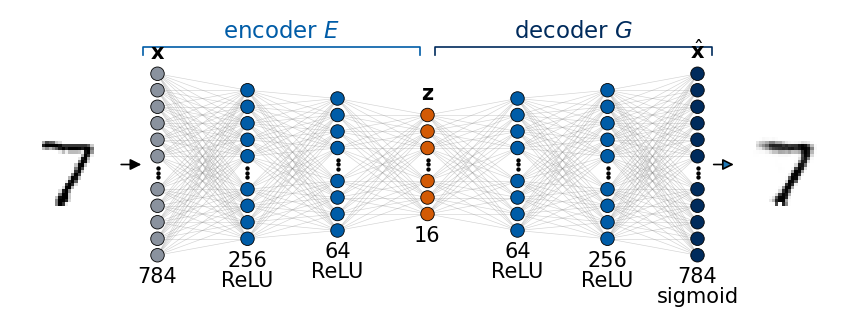

In [6]:
class DenseAE(nnx.Module):
    def __init__(self, d, D=784, hidden=(256, 64), *, rngs):
        h1, h2 = hidden
        self.enc = nnx.List([nnx.Linear(D, h1, rngs=rngs), nnx.Linear(h1, h2, rngs=rngs), nnx.Linear(h2, d, rngs=rngs)])
        self.dec = nnx.List([nnx.Linear(d, h2, rngs=rngs), nnx.Linear(h2, h1, rngs=rngs), nnx.Linear(h1, D, rngs=rngs)])
    def encode(self, x):
        for layer in self.enc[:-1]: x = nnx.relu(layer(x))
        return self.enc[-1](x)
    def decode(self, z):
        for layer in self.dec[:-1]: z = nnx.relu(layer(z))
        return nnx.sigmoid(self.dec[-1](z))

def ae_loss(model, batch, key):
    (x,) = batch
    mse = jnp.mean((model.decode(model.encode(x)) - x) ** 2)
    return mse, {"mse": mse}

print("autoencoder, d = 2");  ae2, _ = train(DenseAE(2, rngs=nnx.Rngs(0)), ae_loss, (Xtr_d,), epochs=12, seed=0, batch_size=256)
print("autoencoder, d = 16"); ae16, _ = train(DenseAE(16, rngs=nnx.Rngs(1)), ae_loss, (Xtr_d,), epochs=12, seed=1, batch_size=256)
ae_encode = nnx.jit(lambda m, x: m.encode(x))
ae_decode = nnx.jit(lambda m, z: m.decode(z))
Z_ae2 = np.asarray(ae_encode(ae2, Xte_d))                       # (10000, 2)
assert Z_ae2.shape == (10000, 2)
Z_ae16_tr = np.asarray(ae_encode(ae16, Xtr_d))

# the d = 16 autoencoder, with the first test digit and its reconstruction at the two ends
x_out = np.asarray(ae_decode(ae16, ae_encode(ae16, Xte_d[:1])))[0]
with mpl.rc_context(SLIDE_RC):
    fig = draw_ae([784, 256, 64], 16, Xte[0], x_out)
    save(fig, "gen_arch_ae.png"); plt.show()

The drawing shows the trained $d=16$ autoencoder with the first test digit and its reconstruction $G(E(\mathbf x))$ at the two ends. The widths $784\to256\to64\to16$ are drawn with 11, 9, 8 and 6 circles, so the bottleneck is visible at once, and the decoder mirrors the encoder. The orange column is the latent vector $\mathbf z$: sixteen numbers that describe this digit, and the only thing the decoder knows about it.

### Decoding a grid of latent points

With $d=2$ the latent space is a plane, and we can look at all of it at once. The next figure has two panels with the same axes $z_1$, $z_2$. The left panel is the latent plane: every coloured dot is the code $\mathbf z=E(\mathbf x)$ of one test digit, coloured by its true label (the labels are used only for the colours, the autoencoder never saw them), and the small black crosses are a regular $10\times10$ grid of latent points. The right panel shows what the decoder makes of these grid points: the cell in column $j$ and row $i$ is the image $G(\mathbf z)$ for $\mathbf z=(z_1^{(j)},z_2^{(i)})$, the grid point at the same position in the left panel, drawn as grey levels from white (pixel value 0) to black (1). The tick labels of the right panel are the latent coordinates of the cell centres, so both panels can be read with the same coordinates; one grid point and its decoded image are marked in red, with an arrow from the point to its image.

The grid values are spaced linearly, ten equal steps between the 1st and the 99th percentile of the codes along each axis. A linear grid over the region of the codes is the only natural choice here: the autoencoder has no probability distribution on its latent plane that could tell us how to space the points (the VAE in Section 5 will have one).

Three things can be read off the figure. Neighbouring cells decode to similar images, because the decoder is a continuous function of $\mathbf z$. Each digit has its own region of the plane, and between two regions the decoded images morph from one digit into the other. Grid points far from all codes, in the empty space between and around the clusters, decode to blurred shapes that are no digit at all: the decoder was never trained there.

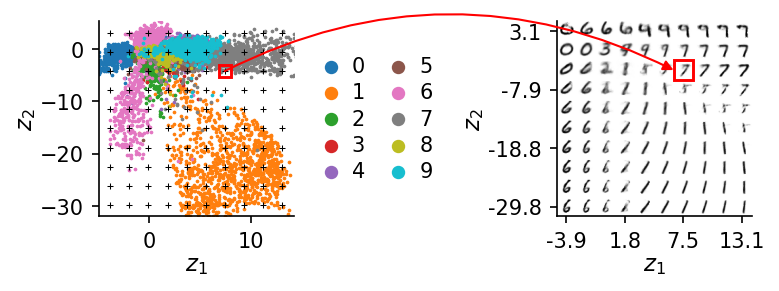

In [7]:
def latent_grid_figure(Z, y, decode, g1, g2, highlight, name=None, prior_circles=False, lim=None, title_left="",
                       title_right=""):
    """Two-panel figure of a 2D latent space at slide size.
    Z, y      : codes (n, 2) of the test digits and their labels (only for the colours)
    decode    : function (m, 2) latent points -> (m, 784) images (the decoder output shown as grey levels)
    g1, g2    : grid values along z_1 and z_2, increasing; the grid points are all pairs (g1[j], g2[i])
    highlight : (j, i), the grid point marked in red in both panels
    prior_circles : draw the circles |z| = 1, 2 of the prior N(0, I) in the left panel
    lim       : ((z1_min, z1_max), (z2_min, z2_max)) of the left panel; default: the grid with a margin"""
    n1, n2 = len(g1), len(g2)
    zz = np.array([[a, b] for b in g2[::-1] for a in g1], np.float32)          # row by row, from the top (largest z_2)
    imgs = np.asarray(decode(jnp.asarray(zz)))
    with mpl.rc_context(SLIDE_RC):
        fig = plt.figure(figsize=(5.5, 1.62))
        axL = fig.add_axes([0.085, 0.185, 0.2364, 0.8025])                      # 1.3 x 1.3 in
        axR = fig.add_axes([0.64, 0.185, 0.2364, 0.8025])
        # ---- left: the codes of the test digits, the grid points, the highlighted point
        for d in range(10):
            m = y == d
            axL.scatter(Z[m, 0], Z[m, 1], s=0.6, color=cmap10(d), rasterized=True, label=str(d))
        G1, G2 = np.meshgrid(g1, g2)
        axL.plot(G1.ravel(), G2.ravel(), "k+", ms=3, mew=0.5)
        if prior_circles:
            t = np.linspace(0, 2 * np.pi, 200)
            for r in (1, 2):
                axL.plot(r * np.cos(t), r * np.sin(t), ":", color="k", lw=0.8)
        j, i = highlight
        axL.plot(g1[j], g2[i], "s", ms=6, mfc="none", mec="red", mew=1.4)
        if lim is None:
            pad1, pad2 = 0.6 * (g1[1] - g1[0]), 0.6 * (g2[1] - g2[0])
            lim = ((g1[0] - pad1, g1[-1] + pad1), (g2[0] - pad2, g2[-1] + pad2))
        axL.set_xlim(*lim[0]); axL.set_ylim(*lim[1])
        axL.set_xlabel("$z_1$", labelpad=1); axL.set_ylabel("$z_2$", labelpad=1); axL.set_title(title_left, fontsize=11)
        axL.legend(markerscale=7, loc="center left", bbox_to_anchor=(1.02, 0.5), handletextpad=0.0, borderaxespad=0.2,
                   labelspacing=0.3, ncol=2, columnspacing=0.6)
        # ---- right: the decoded grid; cell (j, i) at position (j, i), tick labels = latent coordinates
        axR.imshow(mosaic(imgs, n2, n1), cmap="gray_r", vmin=0, vmax=1, extent=(-0.5, n1 - 0.5, -0.5, n2 - 0.5))
        axR.set_xticks(range(0, n1, 3)); axR.set_xticklabels([f"{v:.1f}" for v in g1[::3]])
        axR.set_yticks(range(0, n2, 3)); axR.set_yticklabels([f"{v:.1f}" for v in g2[::3]])
        axR.set_xlabel("$z_1$", labelpad=1); axR.set_ylabel("$z_2$", labelpad=1); axR.set_title(title_right, fontsize=11)
        axR.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="red", lw=1.4))
        fig.add_artist(ConnectionPatch((g1[j], g2[i]), (j - 0.5, i), "data", "data", axesA=axL, axesB=axR,
                                       arrowstyle="-|>", color="red", lw=1.0, connectionstyle="arc3,rad=-0.25"))
        if name: save(fig, name)
        plt.show()
    return imgs

lo, hi = np.percentile(Z_ae2, 1, axis=0), np.percentile(Z_ae2, 99, axis=0)
g1_ae, g2_ae = np.linspace(lo[0], hi[0], 10), np.linspace(lo[1], hi[1], 10)     # linear grid over the codes
imgs_ae_grid = latent_grid_figure(Z_ae2, yte, lambda z: ae_decode(ae2, z), g1_ae, g2_ae, highlight=(6, 7),
                                  name="gen_ae_grid.png")
nums["ae2_grid_highlight"] = [float(g1_ae[6]), float(g2_ae[7])]

In this plane the 1s (orange) occupy a large part of the area, while most other digits are squeezed together near the origin, and the codes of the two coordinates have very different spreads. Many grid points decode to digits, but those in the empty regions between and around the clusters decode to shapes between two digits or to no digit at all. Nothing in the training says where the valid latent vectors are, or how often a region should be used.

### Random latent vectors in 16 dimensions

With $d=16$ we can no longer look at the latent space, so we sample it instead. We draw random latent vectors in two ways: from the standard normal distribution $\mathcal N(0,I)$, and from a Gaussian fitted to the training codes coordinate by coordinate, $z_k\sim\mathcal N(m_k,s_k^2)$, where $m_k$ and $s_k$ are the mean and standard deviation of $E(\mathbf x)_k$ over the training set. The printed standard deviations, between about 1.8 and 3.6, already show that the codes do not follow $\mathcal N(0,I)$.

standard deviations of the 16 code coordinates: [3.47 1.99 1.8  2.42 2.34 2.76 2.69 3.33 2.6  2.43 3.3  2.84 3.57 3.05
 2.27 2.66]


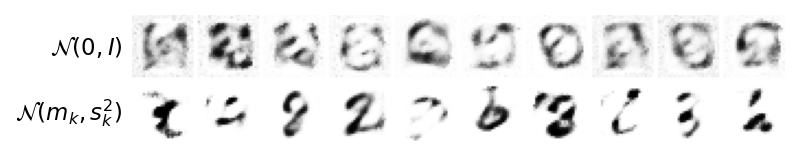

In [8]:
m16, s16 = Z_ae16_tr.mean(0), Z_ae16_tr.std(0)
k1, k2 = jax.random.split(jax.random.key(10))
z_std = jax.random.normal(k1, (2000, 16))
z_fit = m16 + s16 * np.asarray(jax.random.normal(k2, (2000, 16)))
imgs_ae16_std = np.asarray(ae_decode(ae16, z_std))
imgs_ae16_fit = np.asarray(ae_decode(ae16, jnp.asarray(z_fit)))
nums["ae16_code_std_range"] = [float(s16.min()), float(s16.max())]
print("standard deviations of the 16 code coordinates:", np.round(s16, 2))
show_grid(np.concatenate([imgs_ae16_std[:10], imgs_ae16_fit[:10]]), 2, 10, "gen_ae_random16.png", width=5.5,
          label_width=1.15, row_labels=[r"$\mathcal{N}(0, I)$", r"$\mathcal{N}(m_k, s_k^2)$"])

Neither choice works. The codes of an autoencoder do not fill a simple region: they lie on a thin, curved set, and a random point of $\mathbb R^{16}$, even one with the right mean and spread in every coordinate, almost never falls on it; Section 8 measures this with a classifier. To generate we need a latent space whose distribution we know and can sample, and a decoder that has been trained on every region that this distribution uses. The variational autoencoder provides both. Before building it, we need the language of probability and likelihood.

As an exercise, decode the midpoint $\frac12\big(E(\mathbf x_a)+E(\mathbf x_b)\big)$ of the codes of two different test digits with the $d=16$ autoencoder and check whether it is a digit.

<hr/>
## 2. Probability, likelihood, maximum likelihood

A model $p(x\,|\,\theta)$ gives the probability of data $x$ when the parameters are $\theta$. The same formula can be read in two ways. Read as a **probability**, $\theta$ is fixed and $x$ varies; summed over all outcomes $x$ it gives 1. Read as a **likelihood**, the observed data are fixed and $\theta$ varies, $L(\theta)=p(x_{\rm obs}\,|\,\theta)$; this is a function of $\theta$, not a probability distribution over $\theta$, and nothing forces it to integrate to 1.

A coin with probability $\theta$ of heads, tossed 10 times, shows the difference: $p(k\,|\,\theta)=\binom{10}{k}\theta^k(1-\theta)^{10-k}$. We observed $k=7$. The left panel below plots $p(k\,|\,0.5)$ as a distribution over $k$, the right panel $L(\theta)=p(7\,|\,\theta)$ as a function of $\theta$. The printout gives $p(7\,|\,0.5)=0.117$, the maximum of the likelihood at $\theta=0.7$, and $\int_0^1L\,d\theta=1/11$, which confirms that the likelihood is not normalised.

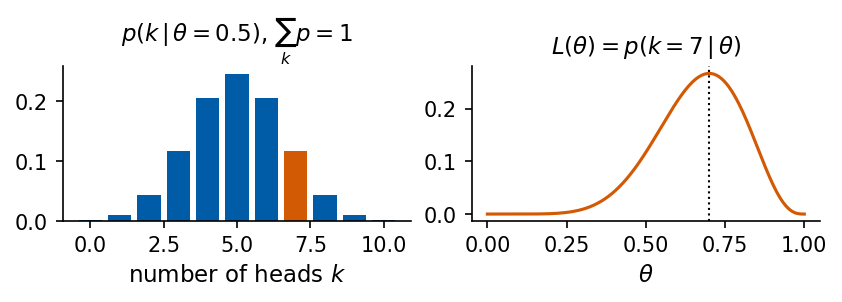

p(7 | 0.5) = 0.117;  argmax L = 0.700;  integral of L over theta = 0.0909 (= 1/11)


In [9]:
ks, th = np.arange(11), np.linspace(0, 1, 401)
p_k = np.array([comb(10, k) * 0.5 ** 10 for k in ks])
L_th = comb(10, 7) * th ** 7 * (1 - th) ** 3
nums["coin_p7_given_half"] = float(p_k[7])
nums["coin_theta_ml"] = float(th[np.argmax(L_th)])
nums["coin_L_integral"] = float(np.trapezoid(L_th, th))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 1.9), layout="constrained")
    axs[0].bar(ks, p_k, color=UJBlue); axs[0].bar([7], [p_k[7]], color=DSOrange)
    axs[0].set_xlabel("number of heads $k$"); axs[0].set_title(r"$p(k\,|\,\theta = 0.5)$, $\sum_k p = 1$")
    axs[1].plot(th, L_th, color=DSOrange); axs[1].axvline(0.7, color="k", ls=":", lw=1)
    axs[1].set_xlabel(r"$\theta$"); axs[1].set_title(r"$L(\theta) = p(k = 7\,|\,\theta)$")
    save(fig, "gen_prob_vs_likelihood.png"); plt.show()
print(f"p(7 | 0.5) = {nums['coin_p7_given_half']:.3f};  argmax L = {nums['coin_theta_ml']:.3f};  "
      f"integral of L over theta = {nums['coin_L_integral']:.4f} (= 1/11)")

### Maximum likelihood

Given data $\mathbf x_1,\dots,\mathbf x_n$, independent samples of an unknown $p(\mathbf x)$, and a model $p_\theta(\mathbf x)$, the likelihood of all the data and its logarithm are
$$L(\theta)=\prod_{i=1}^n p_\theta(\mathbf x_i),\qquad \ell(\theta)=\sum_{i=1}^n\log p_\theta(\mathbf x_i),\qquad \theta^*=\arg\max_\theta\ell(\theta).$$
For $n\to\infty$, $\frac1n\ell(\theta)\to\mathbb E_{p}[\log p_\theta]=-H(p)-\mathrm{KL}(p\,\|\,p_\theta)$, where $H$ is the entropy and KL the Kullback–Leibler divergence. Since $H(p)$ does not depend on $\theta$, maximum likelihood minimises the KL divergence between the data distribution and the model. The cross-entropy loss of classification is minus a log-likelihood of exactly this kind.

As an example we take 1500 points in 2D drawn from three groups and fit two models. The first is one Gaussian, for which $\theta^*$ is known in closed form: the sample mean and the sample covariance (with $1/n$). The second is a mixture of three Gaussians,
$$p_\theta(\mathbf x)=\sum_{k=1}^{3}\pi_k\,\mathcal N(\mathbf x;\boldsymbol\mu_k,\Sigma_k),$$
which has no closed-form maximum. We therefore maximise $\ell$ by **gradient ascent**, exactly as we train a network. The constraints on the parameters are built into the parametrisation: $\pi=\mathrm{softmax}(\mathbf a)$ is automatically a probability vector, and $\Sigma_k=L_kL_k^\top$ with $L_k$ lower-triangular and a positive diagonal $e^{(\cdot)}$ is automatically positive definite. Fitting the single Gaussian by the same gradient ascent tests the procedure against the closed form. Finally we **draw new points** from each fitted model and compare them with the data.

one Gaussian: gradient ascent mean [ 0.579 -0.061] | sample mean [ 0.579 -0.061]
              gradient ascent cov  [[7.144000053405762, -0.6740000247955322], [-0.6740000247955322, 5.1579999923706055]] | sample cov (1/n) [[7.144, -0.674], [-0.674, 5.158]]
mean log-likelihood per point: one Gaussian -4.635, mixture of three -3.679


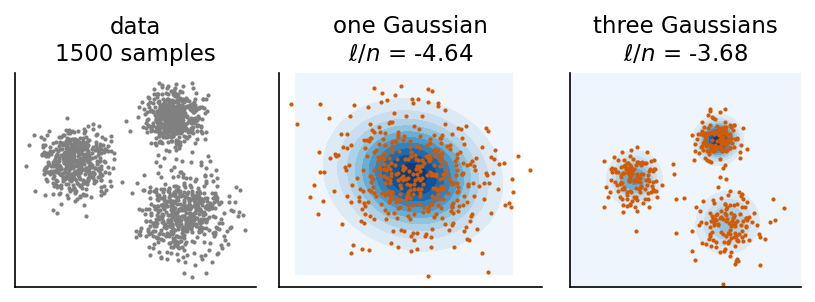

In [10]:
rng = np.random.default_rng(0)
centres, widths = np.array([[-3, 0], [2, 2.5], [2.5, -2.5]]), np.array([0.9, 0.7, 1.1])
lab = rng.integers(0, 3, 1500)
X2 = (centres[lab] + widths[lab, None] * rng.normal(size=(1500, 2))).astype(np.float32)

def gauss_logpdf(x, mu, Lraw):
    """log N(x; mu, L L^T), L lower-triangular with exp on the diagonal."""
    L = jnp.tril(Lraw, -1) + jnp.diag(jnp.exp(jnp.diag(Lraw)))
    u = jax.scipy.linalg.solve_triangular(L, (x - mu).T, lower=True)          # L^{-1} (x - mu)
    return -0.5 * jnp.sum(u ** 2, 0) - jnp.sum(jnp.diag(Lraw)) - jnp.log(2 * jnp.pi)

def mixture_loglik(theta, x):          # log p(x) for every point
    comp = jax.vmap(lambda mu, Lr: gauss_logpdf(x, mu, Lr))(theta["mu"], theta["L"])   # (K, n)
    return jax.scipy.special.logsumexp(jax.nn.log_softmax(theta["a"])[:, None] + comp, axis=0)

def fit_mixture(x, K, steps=3000, lr=0.05):
    first = x[0]; idx = [int(np.argmax(((x - first) ** 2).sum(1)))]     # farthest-point initial means
    while len(idx) < K:
        idx.append(int(np.argmax(np.min([((x - x[j]) ** 2).sum(1) for j in idx], 0))))
    theta = {"a": jnp.zeros(K), "mu": jnp.asarray(x[idx]), "L": jnp.zeros((K, 2, 2))}
    tx = optax.adam(lr); st = tx.init(theta); xj = jnp.asarray(x)
    @jax.jit
    def run(theta, st):
        def step(c, _):
            theta, st = c
            nll, g = jax.value_and_grad(lambda t: -mixture_loglik(t, xj).mean())(theta)
            up, st = tx.update(g, st, theta)
            return (optax.apply_updates(theta, up), st), nll
        return jax.lax.scan(step, (theta, st), None, length=steps)
    (theta, _), nll = run(theta, st)
    return theta, np.asarray(nll)

def sample_mixture(theta, key, n):
    kc, kz = jax.random.split(key)
    c = jax.random.categorical(kc, theta["a"], shape=(n,))
    L = jnp.tril(theta["L"], -1) + jax.vmap(jnp.diag)(jnp.exp(jax.vmap(jnp.diag)(theta["L"])))
    return np.asarray(theta["mu"][c] + jnp.einsum("nij,nj->ni", L[c], jax.random.normal(kz, (n, 2))))

theta1, nll1 = fit_mixture(X2, 1)
theta3, nll3 = fit_mixture(X2, 3)
mean_ml, cov_ml = X2.mean(0), np.cov(X2.T, bias=True)
L1 = np.tril(np.asarray(theta1["L"][0]), -1) + np.diag(np.exp(np.diag(np.asarray(theta1["L"][0]))))
print("one Gaussian: gradient ascent mean", np.round(np.asarray(theta1["mu"][0]), 3), "| sample mean", np.round(mean_ml, 3))
print("              gradient ascent cov ", np.round(L1 @ L1.T, 3).tolist(), "| sample cov (1/n)", np.round(cov_ml, 3).tolist())
nums["mle_loglik_1"], nums["mle_loglik_3"] = float(-nll1[-1]), float(-nll3[-1])
print(f"mean log-likelihood per point: one Gaussian {nums['mle_loglik_1']:.3f}, mixture of three {nums['mle_loglik_3']:.3f}")

xx, yy = np.meshgrid(np.linspace(-7, 7, 200), np.linspace(-6.5, 6.5, 200))
grid2 = jnp.asarray(np.c_[xx.ravel(), yy.ravel()], dtype=jnp.float32)
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 1.9), layout="constrained")
    axs[0].scatter(X2[:, 0], X2[:, 1], s=1, color="grey"); axs[0].set_title("data\n1500 samples")
    for a, theta, name, key in [(axs[1], theta1, "one Gaussian", 1), (axs[2], theta3, "three Gaussians", 2)]:
        dens = np.exp(np.asarray(mixture_loglik(theta, grid2))).reshape(xx.shape)
        a.contourf(xx, yy, dens, levels=12, cmap="Blues")
        new = sample_mixture(theta, jax.random.key(key), 400)          # 400 new points drawn from the fitted model
        a.scatter(new[:, 0], new[:, 1], s=1, color=DSOrange)
        a.set_title(f"{name}\n" + r"$\ell/n$" + f" = {float(mixture_loglik(theta, jnp.asarray(X2)).mean()):.2f}")
    for a in axs: a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal")
    save(fig, "gen_mle_gmm.png"); plt.show()

Gradient ascent reproduces the closed-form mean and covariance of the single Gaussian. The mixture assigns the data a higher likelihood, $-3.679$ against $-4.635$ per point, and its samples (orange) look like the data, while the single Gaussian puts probability where there are no data. For images no closed formula of this kind exists: a neural network must represent $p_\theta(\mathbf x)$.

As an exercise, fit mixtures with $K=2,3,6,12$ components and evaluate $\ell/n$ on the training points and on 1500 fresh points from the same three groups. Find the $K$ at which a larger model stops helping.

### Hidden labels and latent variables

The mixture contains the idea on which the rest of this notebook is built. Read the formula $p_\theta(\mathbf x)=\sum_k\pi_k\,\mathcal N(\mathbf x;\boldsymbol\mu_k,\Sigma_k)$ as a two-stage recipe, which is exactly how `sample_mixture` above produced the orange points. First a hidden label is drawn, the index $k$ of a component, with probability $p(k)=\pi_k$. Then the point is drawn from the Gaussian of that component, $p_\theta(\mathbf x\,|\,k)=\mathcal N(\mathbf x;\boldsymbol\mu_k,\Sigma_k)$. The label is never observed (the data are just points), it is a latent variable, and the probability of a point is the sum over all labels that could have produced it:
$$p_\theta(\mathbf x)=\sum_{k=1}^{K}p(k)\,p_\theta(\mathbf x\,|\,k).$$
We sample in this order: first the hidden cause, then the observation given the cause. It is easy whenever both stages are easy, even if $p_\theta(\mathbf x)$ itself has a complicated shape.

A handwritten digit is not well described by a choice among a few prototypes: the slant, the thickness, the size and the style of the strokes vary continuously. The variational autoencoder therefore replaces the discrete label $k$ by a continuous latent vector $\mathbf z\in\mathbb R^d$, and the sum by an integral,
$$p_\theta(\mathbf x)=\int p(\mathbf z)\,p_\theta(\mathbf x\,|\,\mathbf z)\,d\mathbf z ,$$
with a simple distribution $p(\mathbf z)$ for the hidden cause and a neural network that turns $\mathbf z$ into the parameters of the distribution $p_\theta(\mathbf x|\mathbf z)$ of an image. A mixture with infinitely many components, one for every $\mathbf z$, whose shapes are produced by a network: that is a VAE.

### Probabilities of a latent-variable model

Four distributions appear in every latent-variable model, and the whole VAE is a statement about how they are related. We list them, each with its meaning in words, its form in the toy model of Section 4 (2D points scattered around a curve, with a 1D latent variable $z$ that says where on the curve a point sits), and its form for MNIST.

The prior $p(\mathbf z)$ is the distribution of the hidden cause before any data are seen. It is fixed, not learned: $p(\mathbf z)=\mathcal N(0,I)$, the standard normal distribution in $d$ dimensions. In the toy model it is the distribution of the position along the curve; for MNIST it is a 16-dimensional cloud of "style vectors".

The likelihood, or decoder, $p_\theta(\mathbf x|\mathbf z)$ is the distribution of the observation once the cause is fixed. It is computed by a network with parameters $\theta$. In the toy model it is a small Gaussian around the point $g_\theta(z)$ of the curve; for MNIST it gives each of the 784 pixels its own probability of being black.

The evidence, or marginal likelihood, $p_\theta(\mathbf x)=\int p(\mathbf z)\,p_\theta(\mathbf x|\mathbf z)\,d\mathbf z$ is the distribution of the observations alone, the model of the data. It is what maximum likelihood should maximise, and it is what we sample when we generate: draw $\mathbf z\sim p(\mathbf z)$, then $\mathbf x\sim p_\theta(\mathbf x|\mathbf z)$.

The posterior $p_\theta(\mathbf z|\mathbf x)$ answers the inverse question: given an observed $\mathbf x$, which causes could have produced it? Bayes' rule connects the four,
$$p_\theta(\mathbf z\,|\,\mathbf x)=\frac{p_\theta(\mathbf x\,|\,\mathbf z)\,p(\mathbf z)}{p_\theta(\mathbf x)} .$$
In the toy model the posterior of a data point is a narrow peak at the position of the nearest part of the curve; for a digit it is the small region of style vectors that would decode to it. The posterior requires $p_\theta(\mathbf x)$ in the denominator, the integral over all of $\mathbb R^d$ that we cannot compute for a network decoder. The VAE replaces it by a second network, the encoder $q_\phi(\mathbf z|\mathbf x)$, a Gaussian whose mean and width are predicted from $\mathbf x$, and trains it to be as close as possible to the true posterior.

Physicists know this structure from statistical mechanics. Think of $\mathbf z$ as a macrostate, for example the magnetisation of a ferromagnet, and of $\mathbf x$ as a microstate, a full configuration of $N$ spins. A few macroscopic numbers fix the character of a configuration, and the remaining randomness is spread over the individual spins: given the magnetisation, the spins are drawn with the corresponding bias. In this picture $p(\mathbf z)$ is the distribution of the macrostate, $p_\theta(\mathbf x|\mathbf z)$ produces a microstate compatible with it, and the posterior $p(\mathbf z|\mathbf x)$ reads the macrostate off a microstate, which is what measuring an order parameter on a snapshot does. Lab 025 makes this literal: there $\mathbf x$ is a spin configuration, and the decoder draws every spin independently given $\mathbf z$.

<hr/>
## 3. Variational autoencoder

### 3.1 Clouds instead of points

The autoencoder of Section 1 failed as a generator for two reasons. It had no distribution on its latent space, so we did not know where to draw latent vectors from; and its decoder was trained only on the isolated codes of the training images, so the space between them decodes to nonsense. The variational autoencoder (VAE) repairs both by changing what the two networks compute and what the training asks of them.

### From a discrete set of codes to a continuous distribution

The difference between the two models can be drawn without any training. An autoencoder trained on $N$ images maps them to a discrete set of $N$ latent vectors, a finite cloud of points (left panel of the sketch below). Nothing is defined between or around these points: the training never asked what a latent vector that is not one of the $N$ codes should decode to, so decoding such a point is undefined territory. What we want instead is something continuous: a probability density on the latent space that covers it without holes, so that we can move around in it, interpolate between codes, and draw new latent vectors whose decodings are new samples from an approximation of the distribution of the data. The VAE obtains this density by replacing each point by a small Gaussian cloud $q_\phi(\mathbf z|\mathbf x)$ and pulling all clouds onto the prior $\mathcal N(0,I)$ (middle panel, the shading is the prior density); the overlapping clouds form one continuous region. Generation then draws a new $\mathbf z$ from this density (the star) and decodes it into a new sample in data space, which lies between the training examples instead of on top of one of them (right panel, training examples on a curve, as in the toy model of Section 4).

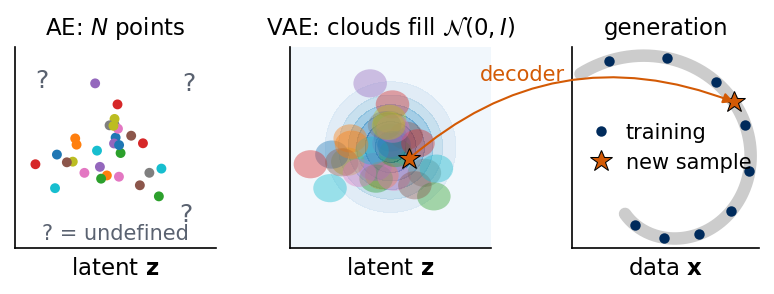

In [11]:
# schematic sketch, no trained model involved: codes, clouds, prior density and a new sample
rng_s = np.random.default_rng(7)
codes = rng_s.normal(size=(30, 2)) * 0.95                              # N latent points (positions are illustrative)
cols = [cmap10(k % 10) for k in range(len(codes))]
z_new = np.array([0.55, -0.35])                                         # a new latent vector drawn from the density
curve = lambda z: np.stack([(1.6 + 0.35 * z) * np.cos(1.25 * z), (1.6 + 0.35 * z) * np.sin(1.25 * z)], -1)
gx, gy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
prior = np.exp(-(gx ** 2 + gy ** 2) / 2)                               # N(0, I) density, unnormalised for the shading
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(1, 3, figsize=(5.5, 1.85), layout="constrained")
    # (1) autoencoder: a discrete set of codes, nothing in between
    ax[0].scatter(codes[:, 0], codes[:, 1], s=14, c=cols, zorder=3)
    for p in [(-2.2, 2.0), (2.1, -2.0), (2.2, 1.9)]:                    # points that are not codes
        ax[0].text(*p, "?", fontsize=12, color=UJGray, ha="center", va="center")
    ax[0].text(0.0, -2.75, "? = undefined", fontsize=10, color=UJGray, ha="center")
    ax[0].set_title("AE: $N$ points")
    # (2) VAE: one Gaussian cloud per code, all pulled onto the prior
    ax[1].contourf(gx, gy, prior, levels=8, cmap="Blues", alpha=0.6)
    for c, col in zip(codes, cols):
        ax[1].add_patch(Ellipse(c, 2 * 0.5, 2 * 0.42, fc=col, ec="none", alpha=0.4))     # cloud mu +- sigma
    ax[1].plot(*z_new, "*", ms=11, color=DSOrange, mec="k", mew=0.5, zorder=4)
    ax[1].set_title(r"VAE: clouds fill $\mathcal{N}(0, I)$")
    # (3) generation: the new z is decoded into a new sample between the training examples
    zz = np.linspace(-1.8, 1.8, 200)
    ax[2].plot(*curve(zz).T, color="0.8", lw=6, solid_capstyle="round")  # where the data live
    zt = np.linspace(-1.6, 1.6, 9)
    ax[2].plot(*curve(zt).T, "o", ms=4, color=UJNavy, label="training")
    ax[2].plot(*curve(np.array([0.6])).T, "*", ms=11, color=DSOrange, mec="k", mew=0.5, label="new sample", zorder=4)
    ax[2].set_title("generation"); ax[2].legend(loc="center", fontsize=10, handletextpad=0.2, borderpad=0.1)
    for a in ax[:2]:
        a.set_xlim(-3, 3); a.set_ylim(-3, 3)
    for a in ax:
        a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
    ax[0].set_xlabel("latent $\\mathbf{z}$"); ax[1].set_xlabel("latent $\\mathbf{z}$"); ax[2].set_xlabel("data $\\mathbf{x}$")
    fig.add_artist(ConnectionPatch(z_new, tuple(curve(np.array([0.6]))[0]), "data", "data", axesA=ax[1], axesB=ax[2],
                                   arrowstyle="-|>", color=DSOrange, lw=1.0, connectionstyle="arc3,rad=-0.3"))
    fig.text(0.66, 0.74, "decoder", fontsize=10, color=DSOrange, ha="center")
    save(fig, "gen_ae_vae_sketch.png"); plt.show()

The model is the latent-variable model of Section 2. A fixed prior $p(\mathbf z)=\mathcal N(0,I_d)$ says where latent vectors live. The decoder is a network $G_\theta:\mathbb R^d\to\mathbb R^{784}$ whose outputs, passed through the sigmoid $\sigma(u)=1/(1+e^{-u})$, are one probability per pixel, $\hat{\mathbf x}=\sigma(G_\theta(\mathbf z))$; the decoder distribution treats the 784 pixels as independent Bernoulli variables (a Bernoulli variable takes the value 1 with probability $\hat x_j$ and 0 otherwise),
$$p_\theta(\mathbf x\,|\,\mathbf z)=\prod_{j=1}^{784}\hat x_j^{\,x_j}(1-\hat x_j)^{1-x_j}.$$
The encoder no longer returns one point per image. It returns a Gaussian cloud of latent vectors,
$$q_\phi(\mathbf z\,|\,\mathbf x)=\mathcal N\big(\boldsymbol\mu_\phi(\mathbf x),\,\mathrm{diag}\,\boldsymbol\sigma_\phi^2(\mathbf x)\big),$$
whose centre $\boldsymbol\mu_\phi(\mathbf x)$ and widths $\boldsymbol\sigma_\phi(\mathbf x)$ ($d$ numbers each) are outputs of a network with parameters $\phi$. The cloud is the set of latent vectors that could have produced $\mathbf x$: it approximates the posterior $p_\theta(\mathbf z|\mathbf x)$ of Section 2.

Training asks two things. Latent vectors drawn from the cloud of $\mathbf x$ must decode back to $\mathbf x$, which forces the decoder to work on whole regions of latent space instead of isolated points. And every cloud must stay close to the prior $\mathcal N(0,I)$, which pulls the clouds of all training images together onto one standard region; they overlap, and the region where the prior puts its probability is filled with latent vectors that the decoder has learned to decode. Both requirements are terms of one objective, the evidence lower bound derived in Section 3.2.

Generation afterwards does not use the encoder at all. It is the two-step sampling of Section 2, applied to $p_\theta(\mathbf x)=\int p(\mathbf z)\,p_\theta(\mathbf x|\mathbf z)\,d\mathbf z$: draw $\mathbf z\sim\mathcal N(0,I)$, then draw the pixels from $p_\theta(\mathbf x|\mathbf z)$, or, as is usual for images, show the pixel probabilities $\hat{\mathbf x}=\sigma(G_\theta(\mathbf z))$ themselves. Because the KL term of the training has filled the prior region with valid codes, a fresh $\mathbf z$ from the prior lands where the decoder knows what to do.

The training needs the likelihood of an image, the marginal
$$\log p_\theta(\mathbf x)=\log\int p_\theta(\mathbf x\,|\,\mathbf z)\,p(\mathbf z)\,d\mathbf z .$$
This integral over $\mathbb R^d$ has no closed form, and estimating it by sampling $\mathbf z$ from the prior fails in practice: for a given image only a tiny region of latent space produces it, so almost all prior samples contribute nothing (Section 5.3 measures this). The encoder is what makes training possible: it tells us where in latent space to look for the $\mathbf z$ that produced a given image.

### 3.2 Evidence lower bound (ELBO)

We start from Bayes' rule, $p(\mathbf x,\mathbf z)=p(\mathbf x|\mathbf z)p(\mathbf z)=p(\mathbf z|\mathbf x)p(\mathbf x)$, the two ways of writing the joint probability of an image and its latent vector. For every $\mathbf z$ it gives $p_\theta(\mathbf x)=p_\theta(\mathbf x|\mathbf z)\,p(\mathbf z)/p_\theta(\mathbf z|\mathbf x)$. Taking the logarithm, and multiplying and dividing by $q_\phi(\mathbf z|\mathbf x)$ inside it, we obtain
$$\log p_\theta(\mathbf x)=\log p_\theta(\mathbf x|\mathbf z)-\log\frac{q_\phi(\mathbf z|\mathbf x)}{p(\mathbf z)}+\log\frac{q_\phi(\mathbf z|\mathbf x)}{p_\theta(\mathbf z|\mathbf x)} .$$

This identity holds for every $\mathbf z$, so it also holds on average over $\mathbf z\sim q_\phi(\mathbf z|\mathbf x)$. The average, or expectation, of a function $f$ over a distribution $q$ is $\mathbb E_{q}[f]=\int q(\mathbf z)\,f(\mathbf z)\,d\mathbf z$; it can be estimated by sampling, $\mathbb E_q[f]\approx\frac1M\sum_m f(\mathbf z_m)$ with $\mathbf z_m\sim q$, which is what makes the result computable. The left-hand side does not depend on $\mathbf z$ and is unchanged by the average. On the right, the averages of the last two terms have the form of the Kullback–Leibler (KL) divergence between two distributions $q$ and $p$ of the same variable,
$$\mathrm{KL}(q\,\|\,p)=\mathbb E_q\Big[\log\frac{q(\mathbf z)}{p(\mathbf z)}\Big]=\int q(\mathbf z)\log\frac{q(\mathbf z)}{p(\mathbf z)}\,d\mathbf z ,$$
the average, over samples of $q$, of the log-ratio of the two densities. It measures how distinguishable $q$ is from $p$: it is zero only for $q=p$ and positive otherwise, and in nats (natural logarithms) a value of 1 means that a typical sample of $q$ is $e$ times more probable under $q$ than under $p$. It is not symmetric, $\mathrm{KL}(q\|p)\neq\mathrm{KL}(p\|q)$ in general. With it the average of the identity reads
$$
\begin{aligned}
\log p_\theta(\mathbf x)={}&\underbrace{\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[\log p_\theta(\mathbf x|\mathbf z)\big]-\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z)\big)}_{\mathrm{ELBO}(\theta,\phi;\,\mathbf x)}\\
&+\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p_\theta(\mathbf z|\mathbf x)\big).
\end{aligned}
$$

The positivity of the KL divergence, Gibbs' inequality, follows from Jensen's inequality for the concave logarithm, $\mathbb E[\log Y]\le\log\mathbb E[Y]$ (the logarithm of an average is at least the average of the logarithms):
$$-\mathrm{KL}(q\|p)=\mathbb E_q\Big[\log\frac pq\Big]\le\log\mathbb E_q\Big[\frac pq\Big]=\log\int p\,d\mathbf z=\log1=0 .$$
The last term is a KL divergence and therefore never negative, so dropping it gives the bound
$$\log p_\theta(\mathbf x)\ \ge\ \mathrm{ELBO}(\theta,\phi;\mathbf x).$$
This is the evidence lower bound (ELBO): "evidence" is the traditional name of $p_\theta(\mathbf x)$, the probability that the model assigns to the observed data, and the ELBO is a lower bound on its logarithm that, unlike $\log p_\theta(\mathbf x)$, can be computed. It is measured in nats per image; for a model of binary $28\times28$ images, uniformly random pixels would give $784\log\tfrac12=-543$ nats, and a good model gives values around $-100$. The gap between the two sides is $\mathrm{KL}(q_\phi\,\|\,p_\theta(\mathbf z|\mathbf x))$, so the bound is tight when the encoder equals the true posterior. Maximising the ELBO over $\theta$ and $\phi$ therefore does two things at once: it pushes $\log p_\theta(\mathbf x)$ up, which is approximate maximum likelihood, and it pushes $q_\phi$ towards the true posterior.

Physicists know the ELBO under another name, the variational free energy. In statistical mechanics, a system with states $\mathbf z$ of energy $E(\mathbf z)$ at temperature $T$ is in the Boltzmann distribution $e^{-E(\mathbf z)/T}/Z$, with partition function $Z=\int e^{-E/T}d\mathbf z$ and free energy $F=-T\log Z$. For any trial distribution $q$ one defines $F[q]=\langle E\rangle_q-T\,S[q]$, with the entropy $S[q]=-\mathbb E_q\log q$; it is smallest, and equal to $F$, for the Boltzmann distribution. Now define an "energy" of the latent configuration $\mathbf z$ for a fixed image, $E(\mathbf z)=-\log\big[p_\theta(\mathbf x|\mathbf z)p(\mathbf z)\big]$, at temperature $T=1$. Its Boltzmann distribution is the posterior, $e^{-E(\mathbf z)}/Z=p_\theta(\mathbf z|\mathbf x)$, with partition function $Z=\int e^{-E}d\mathbf z=p_\theta(\mathbf x)$ and free energy $F=-\log Z=-\log p_\theta(\mathbf x)$. For a trial distribution $q$, the variational free energy is
$$F[q]=\langle E\rangle_q-S[q],\qquad S[q]=-\mathbb E_q\log q ,$$
and inserting $E=-\log Z-\log(e^{-E}/Z)$ into $\langle E\rangle_q$ gives $F[q]=F+\mathrm{KL}(q\,\|\,e^{-E}/Z)\ge F$, the Gibbs–Bogoliubov inequality behind mean-field theory. Comparing with the ELBO, $F[q]=-\mathrm{ELBO}$. Training a VAE is minimising a variational free energy, with a Gaussian trial distribution produced by a network for each image.

### 3.3 VAE loss

Per image we minimise $-\mathrm{ELBO}$, a sum of two terms with clear roles.

The first term is the reconstruction error. For the Bernoulli decoder of Section 3.1 the negative log-likelihood of an image is the binary cross-entropy (BCE),
$$-\log p_\theta(\mathbf x|\mathbf z)=\mathrm{BCE}(\mathbf x,\hat{\mathbf x})=-\sum_{j=1}^{784}\big[x_j\log\hat x_j+(1-x_j)\log(1-\hat x_j)\big],$$
with $\hat{\mathbf x}=\sigma(G_\theta(\mathbf z))$.
For one pixel with $x_j=1$ it is $-\log\hat x_j$, the surprise of the model at seeing a black pixel when it predicted the probability $\hat x_j$: zero for $\hat x_j=1$, $\log2=0.69$ nats for an undecided $\hat x_j=\tfrac12$, and large when the model was confidently wrong. Summed over pixels it measures, in nats, how badly the predicted probabilities explain the image. It is the right reconstruction error here, rather than the squared error of Section 1, because it is exactly the term $\mathbb E_q[\log p_\theta(\mathbf x|\mathbf z)]$ of the ELBO for a Bernoulli decoder; MNIST pixels are grey values in $[0,1]$ rather than 0 or 1, but the BCE remains a valid loss (it is smallest at $\hat x_j=x_j$) and is the standard choice. The expectation over $q_\phi$ is estimated with one sample $\mathbf z\sim q_\phi(\mathbf z|\mathbf x)$ per image (Section 3.5). On its own, this term would shrink every cloud to a point and move the clouds apart, which gives back an ordinary autoencoder.

The second term is $\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z)\big)$, which for two Gaussians has the closed form derived in Section 3.4,
$$\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,\mathcal N(0,I)\big)=\tfrac12\sum_{k=1}^{d}\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big).$$
It is the price of information. A cloud equal to the prior, $\boldsymbol\mu=0$, $\boldsymbol\sigma=1$, costs nothing, but it also says nothing about the image, since every image would get the same cloud. To distinguish images the encoder must move the clouds away from the origin ($\mu_k^2$) and make them narrower than the prior ($-\ln\sigma_k^2$), and every such step costs nats. The KL term thus measures how much information about $\mathbf x$ the latent vector carries, and the training spends this information only where it buys a better reconstruction. The pull towards the prior has a second effect, the one we need for generation: the clouds of all images overlap and cover the region where $\mathcal N(0,I)$ puts its probability, so a fresh $\mathbf z\sim\mathcal N(0,I)$ decodes to a valid image.

Altogether the loss per image is
$$
\begin{aligned}
\mathcal L(\mathbf x)={}&\mathrm{BCE}\big(\mathbf x,\sigma(G_\theta(\mathbf z))\big)\\
&+\tfrac12\sum_{k=1}^{d}\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big),\qquad\mathbf z\sim q_\phi(\mathbf z|\mathbf x),
\end{aligned}
$$
averaged over a minibatch and measured in nats per image.

References: D. P. Kingma, M. Welling, *Auto-Encoding Variational Bayes*, ICLR 2014, [arXiv:1312.6114](https://arxiv.org/abs/1312.6114); D. J. Rezende, S. Mohamed, D. Wierstra, *Stochastic Backpropagation and Approximate Inference in Deep Generative Models*, ICML 2014, [PMLR 32, 1278](https://proceedings.mlr.press/v32/rezende14.html); review: D. P. Kingma, M. Welling, *An Introduction to Variational Autoencoders*, Found. Trends Mach. Learn. **12**, 307 (2019), [doi:10.1561/2200000056](https://doi.org/10.1561/2200000056).

### 3.4 KL divergence between two Gaussians

The KL term of the loss can be computed exactly. For one latent coordinate, with $q=\mathcal N(\mu,\sigma^2)$ and $p=\mathcal N(0,1)$, the logarithms of the Gaussian densities $\mathcal N(z;\mu,\sigma^2)=e^{-(z-\mu)^2/2\sigma^2}/\sqrt{2\pi\sigma^2}$ are
$$\log q(z)=-\tfrac12\log(2\pi\sigma^2)-\frac{(z-\mu)^2}{2\sigma^2},\qquad \log p(z)=-\tfrac12\log(2\pi)-\frac{z^2}{2}.$$
Averaging the difference over $z\sim q$ and using $\mathbb E_q[(z-\mu)^2]=\sigma^2$ and $\mathbb E_q[z^2]=\mu^2+\sigma^2$ gives
$$\mathrm{KL}(q\,\|\,p)=\mathbb E_q[\log q-\log p]=-\tfrac12\log\sigma^2-\tfrac12+\tfrac12(\mu^2+\sigma^2)=\tfrac12\big(\mu^2+\sigma^2-\ln\sigma^2-1\big).$$
For a diagonal Gaussian in $d$ dimensions, $\log q$ and $\log p$ are sums over coordinates, so the KL divergence is the sum of $d$ such terms. It is zero only for $\mu=0$, $\sigma=1$. The encoder outputs $\log\sigma^2$ rather than $\sigma$, because any real number is then allowed and $\sigma^2=e^{\log\sigma^2}>0$ holds automatically.

To make sure the formula and its implementation are right, the next cell compares the closed form with a Monte Carlo estimate $\frac1M\sum_m[\log q(z_m)-\log p(z_m)]$ using $M=10^6$ samples $z_m\sim q$, for three choices of $(\mu,\sigma)$. The two agree to within the Monte Carlo error, a few thousandths of a nat.

In [12]:
def kl_per_dim(mu, logvar):
    """KL( N(mu, sigma^2) || N(0, 1) ) for every latent coordinate; sigma^2 = exp(logvar). Same shape as mu."""
    return 0.5 * (mu ** 2 + jnp.exp(logvar) - logvar - 1)

def log_normal(z, mu, logvar):
    """log N(z; mu, sigma^2), elementwise."""
    return -0.5 * (jnp.log(2 * jnp.pi) + logvar + (z - mu) ** 2 / jnp.exp(logvar))

for mu_t, sigma_t in [(0.0, 1.0), (1.5, 0.5), (-0.3, 2.0)]:
    z = mu_t + sigma_t * jax.random.normal(jax.random.key(0), (1_000_000,))          # samples of q
    lv = jnp.log(sigma_t ** 2)
    kl_mc = jnp.mean(log_normal(z, mu_t, lv) - log_normal(z, 0.0, 0.0))
    kl_cf = kl_per_dim(jnp.asarray(mu_t), lv)
    print(f"mu = {mu_t:5.2f}, sigma = {sigma_t:4.2f}:   KL closed form = {float(kl_cf):.4f}   KL Monte Carlo = {float(kl_mc):.4f}")
    assert abs(float(kl_cf) - float(kl_mc)) < 5e-3

mu =  0.00, sigma = 1.00:   KL closed form = 0.0000   KL Monte Carlo = 0.0000
mu =  1.50, sigma = 0.50:   KL closed form = 1.4431   KL Monte Carlo = 1.4441
mu = -0.30, sigma = 2.00:   KL closed form = 0.8519   KL Monte Carlo = 0.8484


### 3.5 Reparametrisation trick

The reconstruction term is an average over $q_\phi$, and we estimate it with one sample $\mathbf z\sim q_\phi(\mathbf z|\mathbf x)$ per image; the average over the minibatch and over training steps does the rest. The loss then depends on $\phi$ through a random draw, and this creates a problem for training. A sampling routine is not a differentiable function of $\boldsymbol\mu,\boldsymbol\sigma$: if we draw $\mathbf z$ and then change $\boldsymbol\mu$ slightly, there is no rule that says how this particular $\mathbf z$ should move, so backpropagation cannot pass from the decoder into the encoder.

The solution is to write the same random variable as a deterministic function of the parameters and of a parameter-free noise,
$$\mathbf z=\boldsymbol\mu_\phi(\mathbf x)+\boldsymbol\sigma_\phi(\mathbf x)\odot\boldsymbol\varepsilon,\qquad\boldsymbol\varepsilon\sim\mathcal N(0,I),\qquad\boldsymbol\sigma=e^{\frac12\log\boldsymbol\sigma^2},$$
where $\odot$ is the element-wise product. This $\mathbf z$ has exactly the distribution $\mathcal N(\boldsymbol\mu,\mathrm{diag}\,\boldsymbol\sigma^2)$, but now $\partial z_k/\partial\mu_k=1$ and $\partial z_k/\partial\sigma_k=\varepsilon_k$, and for any function $f$
$$\nabla_{\mu,\sigma}\,\mathbb E_{\mathbf z\sim q}[f(\mathbf z)]=\mathbb E_{\boldsymbol\varepsilon}\big[\nabla_{\mu,\sigma}f(\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon)\big],$$
an average of ordinary gradients that backpropagation computes. In JAX, $\boldsymbol\varepsilon$ is drawn from an explicit key, `jax.random.normal(key, mu.shape)`, and `jax.grad` differentiates through $\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon$.

We test the trick on a case with a known answer. For $f(z)=z^2$, $\mathbb E_q[z^2]=\mu^2+\sigma^2$, so $\partial/\partial\mu=2\mu$ and $\partial/\partial\sigma=2\sigma$. The next cell applies `jax.grad` to the reparametrised Monte Carlo average and compares the result with these exact derivatives; with $2\times10^5$ samples they agree to better than one percent.

In [13]:
def mc_average_of_z2(params, key, n_samples=200_000):
    """(1/M) sum_m f(mu + sigma * eps_m) with f(z) = z^2; differentiable in (mu, sigma)."""
    mu, sigma = params
    eps = jax.random.normal(key, (n_samples,))        # parameter-free noise
    z = mu + sigma * eps                              # reparametrised sample of N(mu, sigma^2)
    return jnp.mean(z ** 2)

mu_t, sigma_t = 0.7, 1.3
g_mu, g_sigma = jax.grad(mc_average_of_z2)((mu_t, sigma_t), jax.random.key(1))
print(f"d/dmu    E[z^2]:  reparametrisation {float(g_mu):.4f}   exact 2 mu    = {2 * mu_t:.4f}")
print(f"d/dsigma E[z^2]:  reparametrisation {float(g_sigma):.4f}   exact 2 sigma = {2 * sigma_t:.4f}")
assert abs(float(g_mu) - 2 * mu_t) < 0.02 and abs(float(g_sigma) - 2 * sigma_t) < 0.02

d/dmu    E[z^2]:  reparametrisation 1.4060   exact 2 mu    = 1.4000
d/dsigma E[z^2]:  reparametrisation 2.5935   exact 2 sigma = 2.6000


<hr/>
## 4. Toy VAE on a curve

Before training on images, where the latent space has 16 dimensions and the data 784, we train a VAE on a problem in which every ingredient can be drawn. The data are points $\mathbf x\in\mathbb R^2$ generated by exactly the kind of latent-variable model a VAE assumes. A hidden number $z_{\rm true}\sim\mathcal N(0,1)$ chooses a position along a spiral,
$$\mathbf f(z)=r(z)\begin{pmatrix}\cos 1.25z\\ \sin 1.25z\end{pmatrix},\qquad r(z)=1.6+0.35z ,$$
and the point is placed near it with a small Gaussian scatter, $\mathbf x=\mathbf f(z_{\rm true})+s\,\boldsymbol\eta$, $\boldsymbol\eta\sim\mathcal N(0,I_2)$, $s=0.08$. The VAE sees only the 4000 points $\mathbf x_i$, not $z_{\rm true}$ and not the curve.

The model has a one-dimensional latent variable $z$ with prior $p(z)=\mathcal N(0,1)$. The decoder is a small network $\mathbf g_\theta:\mathbb R\to\mathbb R^2$ ($1\to64\to64\to2$, tanh activations), and $p_\theta(\mathbf x|z)=\mathcal N(\mathbf x;\mathbf g_\theta(z),s^2I_2)$ is a Gaussian of the known width $s$ around the decoded point; its negative logarithm, $\lVert\mathbf x-\mathbf g_\theta(z)\rVert^2/2s^2+\log(2\pi s^2)$, replaces the BCE of the images. The encoder ($2\to64\to64\to(\mu,\log\sigma^2)$) returns a Gaussian $q_\phi(z|\mathbf x)=\mathcal N(\mu_\phi(\mathbf x),\sigma_\phi^2(\mathbf x))$ on the latent line for each point. The loss is the same $-\mathrm{ELBO}$ as in Section 3.3, with the same KL term.

After training we draw everything in one figure. The left panel is the data space: the training points (grey), the decoder curve $\mathbf g_\theta(z)$ for $z\in[-3,3]$ (navy, with ticks at $z=-2,\dots,2$), and 500 new points generated in two steps, $z\sim\mathcal N(0,1)$ followed by $\mathbf x\sim\mathcal N(\mathbf g_\theta(z),s^2I)$ (orange). Four training points are marked in colour. The right panel is the latent line. It shows the prior $p(z)$ (dashed), the aggregate posterior
$$q_\phi(z)=\frac1n\sum_{i=1}^{n}q_\phi(z\,|\,\mathbf x_i),$$
the average of the encoder clouds of all training points, which is the distribution of latent values that the encoded data actually occupy (navy), and, as coloured bars, the encoder clouds $\mu_\phi(\mathbf x)\pm\sigma_\phi(\mathbf x)$ of the four marked points.

In [14]:
def spiral(z):
    """The true curve f(z) of the toy data: radius 1.6 + 0.35 z, angle 1.25 z."""
    r = 1.6 + 0.35 * z
    return np.stack([r * np.cos(1.25 * z), r * np.sin(1.25 * z)], -1)

S_TOY = 0.08                                               # scatter of the points around the curve
rng_toy = np.random.default_rng(4)
z_true = rng_toy.normal(size=4000)
X_toy = (spiral(z_true) + S_TOY * rng_toy.normal(size=(4000, 2))).astype(np.float32)

class ToyVAE(nnx.Module):
    """VAE with a 1D latent: encoder 2 -> 64 -> 64 -> (mu, log sigma^2); decoder 1 -> 64 -> 64 -> point of R^2."""
    def __init__(self, *, rngs):
        self.enc = nnx.List([nnx.Linear(2, 64, rngs=rngs), nnx.Linear(64, 64, rngs=rngs)])
        self.mu, self.logvar = nnx.Linear(64, 1, rngs=rngs), nnx.Linear(64, 1, rngs=rngs)
        self.dec = nnx.List([nnx.Linear(1, 64, rngs=rngs), nnx.Linear(64, 64, rngs=rngs), nnx.Linear(64, 2, rngs=rngs)])
    def encode(self, x):
        for layer in self.enc: x = nnx.tanh(layer(x))
        return self.mu(x), self.logvar(x)                   # (B, 1) each
    def decode(self, z):
        for layer in self.dec[:-1]: z = nnx.tanh(layer(z))
        return self.dec[-1](z)                              # (B, 2): the centre g(z) of p(x|z)

def toy_loss(model, batch, key):
    """-ELBO per point: Gaussian reconstruction term with the known width S_TOY, plus the KL term."""
    (x,) = batch
    mu, logvar = model.encode(x)
    z = mu + jnp.exp(0.5 * logvar) * jax.random.normal(key, mu.shape)
    rec = (((x - model.decode(z)) ** 2).sum(-1) / (2 * S_TOY ** 2) + jnp.log(2 * jnp.pi * S_TOY ** 2)).mean()
    kl = (0.5 * (mu ** 2 + jnp.exp(logvar) - logvar - 1)).sum(-1).mean()
    return rec + kl, {"loss": rec + kl, "rec": rec, "kl": kl}

print("toy VAE"); toy, h_toy = train(ToyVAE(rngs=nnx.Rngs(40)), toy_loss, (jnp.asarray(X_toy),), epochs=150, seed=40,
                                     batch_size=100, lr=3e-3, log_every=50)
mu_toy, lv_toy = [np.asarray(a)[:, 0] for a in toy.encode(jnp.asarray(X_toy))]
sig_toy = np.exp(0.5 * lv_toy)
nums["toy"] = {"elbo": -float(h_toy["loss"][-1]), "kl": float(h_toy["kl"][-1]), "sigma_median": float(np.median(sig_toy)),
               "corr_mu_ztrue": float(abs(np.corrcoef(mu_toy, z_true)[0, 1])),
               "aggpost_mean": float(mu_toy.mean()), "aggpost_std": float(np.sqrt(mu_toy.var() + (sig_toy ** 2).mean()))}
print({k: round(v, 3) for k, v in nums["toy"].items()})

toy VAE


  epoch   1: kl 4.1862  loss 118.4088  rec 114.2226   (  1.0 s)


  epoch  50: kl 3.3106  loss 1.8596  rec -1.4510   (  1.7 s)


  epoch 100: kl 3.2861  loss 1.7567  rec -1.5293   (  2.3 s)


  epoch 150: kl 3.3663  loss 1.5793  rec -1.7870   (  2.9 s)


{'elbo': -1.579, 'kl': 3.366, 'sigma_median': 0.042, 'corr_mu_ztrue': 0.993, 'aggpost_mean': -0.021, 'aggpost_std': 1.037}


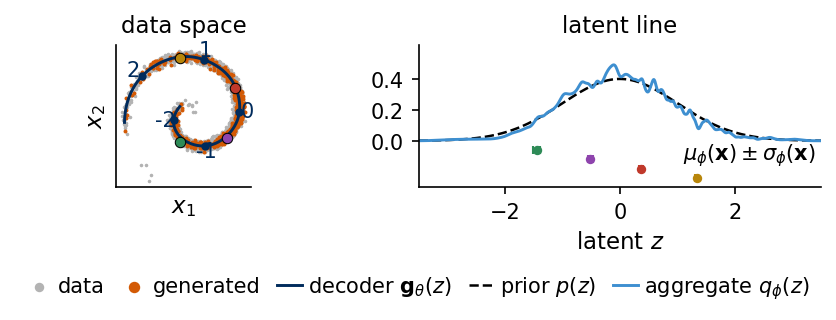

In [15]:
zline = np.linspace(-3, 3, 400)[:, None].astype(np.float32)
curve = np.asarray(toy.decode(jnp.asarray(zline)))
zt = np.arange(-2, 3)[:, None].astype(np.float32); curve_t = np.asarray(toy.decode(jnp.asarray(zt)))
kz, kx = jax.random.split(jax.random.key(41))
z_gen = np.asarray(jax.random.normal(kz, (500, 1)))
x_gen = np.asarray(toy.decode(jnp.asarray(z_gen))) + S_TOY * np.asarray(jax.random.normal(kx, (500, 2)))
pick = [int(np.argmin(np.abs(z_true - v))) for v in (-1.6, -0.5, 0.4, 1.5)]   # four marked training points
pick_col = ["#2E8B57", "#8E44AD", "#C0392B", "#B8860B"]
zz = np.linspace(-3.5, 3.5, 701)
q_agg = norm.pdf(zz[:, None], mu_toy[None], sig_toy[None]).mean(1)            # aggregate posterior on a grid

with mpl.rc_context(SLIDE_RC):
    fig, (a, b) = plt.subplots(1, 2, figsize=(5.5, 2.05), layout="constrained", gridspec_kw=dict(width_ratios=[1, 1.15]))
    a.scatter(X_toy[:, 0], X_toy[:, 1], s=0.5, color="0.7", rasterized=True, label="data")
    a.scatter(x_gen[:, 0], x_gen[:, 1], s=0.8, color=DSOrange, rasterized=True, label="generated")
    a.plot(curve[:, 0], curve[:, 1], color=UJNavy, lw=1.4, label=r"decoder $\mathbf{g}_\theta(z)$")
    a.plot(curve_t[:, 0], curve_t[:, 1], "o", color=UJNavy, ms=3)
    for zv, (px, py) in zip(zt[:, 0], curve_t):                               # tick labels z = -2, ..., 2 on the curve
        dx_, dy_ = (-0.3, 0.0) if zv == -2 else (0.17 * px, 0.17 * py)
        a.text(px + dx_, py + dy_, f"{zv:.0f}", fontsize=10, ha="center", va="center", color=UJNavy)
    for k, c in zip(pick, pick_col):
        a.plot(*X_toy[k], "o", ms=5, mfc=c, mec="k", mew=0.5)
    a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([]); a.set_xlabel("$x_1$"); a.set_ylabel("$x_2$")
    a.set_title("data space")
    b.plot(zz, norm.pdf(zz), "--", color="k", lw=1.2, label=r"prior $p(z)$")
    b.plot(zz, q_agg, color="#3E8FD0", lw=1.4, label=r"aggregate $q_\phi(z)$")
    for j, (k, c) in enumerate(zip(pick, pick_col)):
        yb = -0.06 - 0.06 * j
        b.errorbar(mu_toy[k], yb, xerr=sig_toy[k], fmt="o", ms=3.5, color=c, capsize=2, lw=1.2)
    b.text(3.4, -0.09, r"$\mu_\phi(\mathbf{x})\pm\sigma_\phi(\mathbf{x})$", fontsize=10, ha="right", va="center")
    b.set_xlim(-3.5, 3.5); b.set_ylim(-0.3, 0.62); b.set_yticks([0, 0.2, 0.4])
    b.set_xlabel("latent $z$"); b.set_title("latent line")
    fig.legend(loc="outside lower center", ncol=5, handlelength=1.2, columnspacing=0.8, handletextpad=0.3, markerscale=5)
    save(fig, "gen_toy_vae.png"); plt.show()

The figure shows the whole VAE at work. The decoder has learned the spiral: the navy curve runs through the middle of the data, and moving $z$ from $-2$ to $2$ moves the decoded point along it, which is what a one-dimensional description of these data must do. Each data point is encoded into a narrow cloud on the latent line (median width $\sigma_\phi$ printed above), at the position along the curve where the point sits: the four coloured points appear on the latent line in the same order in which they lie on the spiral, and $|\mathrm{corr}(\mu_\phi,z_{\rm true})|$ is close to 1. The latent variable has recovered the hidden cause, up to its sign and a smooth reparametrisation, without ever seeing it.

The clouds are narrow, much narrower than the prior, because a point carries a lot of information about its position on the curve; this is what the KL term charges for, here a few nats per point. Taken together, the clouds of all points form the aggregate posterior $q_\phi(z)$, and it lies close to the prior: its mean and standard deviation are near 0 and 1. This is the effect of the KL term that matters for generation. The prior region is filled by encoded data, so a $z$ drawn from the prior lands where the decoder has been trained, and the generated orange points fall on the data. Where the aggregate posterior and the prior differ, the generated points are distributed along the curve with slightly different density from the data; with images, the same mismatch produces the "prior holes" of Section 6.3. The small wiggles of $q_\phi(z)$ come from adding up 4000 narrow clouds; they are features of the trained encoder, not noise of the plot.

The toy model also shows what the decoder variance does. A generated point is $\mathbf g_\theta(z)$ plus Gaussian scatter of width $s$; without the scatter all generated points would lie exactly on the curve. For images the corresponding choice is between showing the decoder mean, the pixel probabilities $\hat{\mathbf x}$, and drawing every pixel from its Bernoulli distribution (Section 6.2).

<hr/>
## 5. VAE on MNIST

### 5.1 Network

The VAE for MNIST is a dense network. The table lists the shapes for a minibatch of $B$ images, latent dimension $d$ and an optional condition with $C$ numbers. The condition is used only in Section 9; here $C=0$.

| quantity | shape | layer |
|---|---|---|
| input $\mathbf x$ (and condition $\mathbf c$) | $(B,784)$ (and $(B,C)$) | |
| encoder hidden layers | $(B,400)\to(B,200)$ | dense + ReLU on $[\mathbf x,\mathbf c]$ |
| $\boldsymbol\mu$, $\log\boldsymbol\sigma^2$ | $(B,d)$ each | two separate linear heads |
| $\boldsymbol\varepsilon$, $\mathbf z$ | $(B,d)$ | $\mathbf z=\boldsymbol\mu+e^{\frac12\log\boldsymbol\sigma^2}\odot\boldsymbol\varepsilon$ |
| decoder hidden layers | $(B,200)\to(B,400)$ | dense + ReLU on $[\mathbf z,\mathbf c]$ |
| logits $G_\theta(\mathbf z)$ | $(B,784)$ | linear |

The decoder returns logits, the numbers $G_\theta(\mathbf z)$ before the sigmoid, not probabilities, because `optax.sigmoid_binary_cross_entropy(logits, x)` computes the BCE from the logits in a numerically stable way, with no $\log 0$ when a sigmoid saturates. The sigmoid is applied only when we want to look at the images.

The `VAE` class takes an optional condition `cond` (the number $C$ of extra inputs), so that the conditional VAE of Section 9 is the same class. As a first sanity check, the loss of the untrained network is dominated by the reconstruction term, about 568 nats per image, while the KL term is close to zero: the untrained encoder returns clouds close to the prior, and the untrained decoder predicts pixel probabilities near $\tfrac12$ for all images.

In [16]:
class VAE(nnx.Module):
    """Dense (conditional) VAE.
    encoder: [x, c] (B, 784 + C) -> 400 -> 200 -> mu (B, d), logvar (B, d)
    decoder: [z, c] (B, d + C)   -> 200 -> 400 -> pixel logits (B, 784)"""
    def __init__(self, d, cond=0, D=784, hidden=(400, 200), *, rngs):
        h1, h2 = hidden
        self.d, self.cond = d, cond
        self.enc = nnx.List([nnx.Linear(D + cond, h1, rngs=rngs), nnx.Linear(h1, h2, rngs=rngs)])
        self.mu = nnx.Linear(h2, d, rngs=rngs)              # head 1: the means
        self.logvar = nnx.Linear(h2, d, rngs=rngs)          # head 2: log sigma^2, any real number
        self.dec = nnx.List([nnx.Linear(d + cond, h2, rngs=rngs), nnx.Linear(h2, h1, rngs=rngs), nnx.Linear(h1, D, rngs=rngs)])

    def encode(self, x, c=None):
        """q_phi(z | x [, c]): returns (mu, logvar), each (B, d)."""
        h = x if c is None else jnp.concatenate([x, c], axis=-1)     # (B, 784 + C)
        for layer in self.enc:
            h = nnx.relu(layer(h))
        return self.mu(h), self.logvar(h)

    def decode(self, z, c=None):
        """G_theta(z [, c]): pixel logits (B, 784); sigmoid(logits) are the Bernoulli probabilities."""
        h = z if c is None else jnp.concatenate([z, c], axis=-1)     # (B, d + C)
        for layer in self.dec[:-1]:
            h = nnx.relu(layer(h))
        return self.dec[-1](h)

def reparametrise(mu, logvar, key):
    """z = mu + sigma * eps, eps ~ N(0, I); the only random step of the VAE."""
    eps = jax.random.normal(key, mu.shape)
    return mu + jnp.exp(0.5 * logvar) * eps

def vae_loss(model, batch, key):
    """-ELBO per image, averaged over the minibatch. batch = (x,) for the VAE, (x, c) for the cVAE."""
    x, c = batch if len(batch) == 2 else (batch[0], None)
    mu, logvar = model.encode(x, c)                                     # (B, d), (B, d)
    z = reparametrise(mu, logvar, key)                                  # (B, d): one sample per image
    rec = optax.sigmoid_binary_cross_entropy(model.decode(z, c), x).sum(axis=-1).mean()   # sum over pixels, mean over images
    kl = kl_per_dim(mu, logvar).sum(axis=-1).mean()                     # sum over latent coordinates, mean over images
    return rec + kl, {"loss": rec + kl, "rec": rec, "kl": kl}

# shape checks on a minibatch of 5 images
_m = VAE(16, rngs=nnx.Rngs(0))
_mu, _lv = _m.encode(Xtr_d[:5])
assert _mu.shape == _lv.shape == (5, 16)
assert _m.decode(reparametrise(_mu, _lv, jax.random.key(0))).shape == (5, 784)
print("parameters of the VAE (d = 16):", sum(p.size for p in jax.tree_util.tree_leaves(nnx.state(_m, nnx.Param))))
print("loss of the untrained VAE (nats per image):", {k: round(float(v), 1) for k, v in vae_loss(_m, (Xtr_d[:256],), jax.random.key(0))[1].items()})

vae_enc = nnx.jit(lambda m, x: m.encode(x))                    # (mu, logvar)
vae_dec = nnx.jit(lambda m, z: jax.nn.sigmoid(m.decode(z)))    # pixel probabilities in (0, 1)

parameters of the VAE (d = 16): 798816


loss of the untrained VAE (nats per image): {'loss': 567.8, 'rec': 567.6, 'kl': 0.2}


The drawing below shows this network with nodes and edges, for $d=16$. Compared with the autoencoder there are three differences, all in the middle. The last encoder layer feeds two separate heads, $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$ (orange columns), that together describe the cloud $q_\phi(\mathbf z|\mathbf x)$. The noise $\boldsymbol\varepsilon$ (light orange) is a separate input of the network, with no parameters. And the latent vector is computed element-wise, $z_j=\mu_j+\sigma_j\varepsilon_j$: each $z_j$ is joined only to $\mu_j$, $\log\sigma_j^2$ and $\varepsilon_j$ (orange lines, dashed for the noise), which is the reparametrisation of Section 3.5 drawn as a graph. Backpropagation reaches the encoder through the solid orange lines.

Flax NNX can also summarise a model as a table. `nnx.tabulate` runs a method of the model on an example input and lists, for every layer it passes through, the shapes of its inputs and outputs and the shapes and number of its parameters. Since the VAE has no single `__call__`, we tabulate `encode` and `decode` separately; where the drawing shows the structure, the table adds the exact shapes and parameter counts, which add up to the 798 816 parameters printed above.

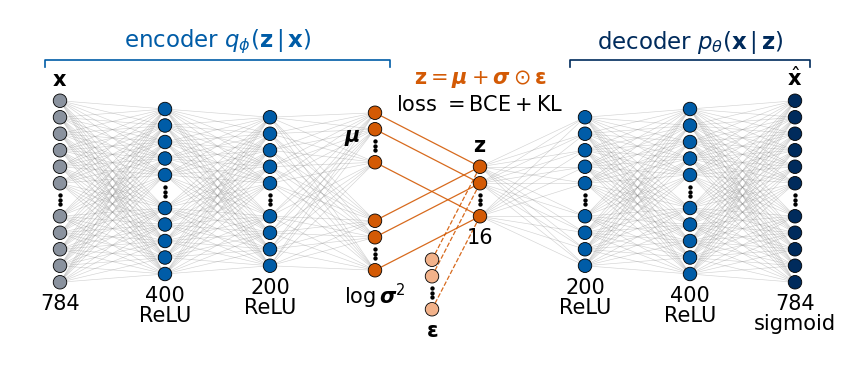

                                  VAE Summary                                   
┏━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path   ┃ type   ┃ inputs         ┃ outputs         ┃ Param                   ┃
┡━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ encode │ VAE    │ float32[1,784] │ - float32[1,16] │ 798,816 (3.2 MB)        │
│        │        │                │ - float32[1,16] │                         │
├────────┼────────┼────────────────┼─────────────────┼─────────────────────────┤
│ mu     │ Linear │ float32[1,200] │ float32[1,16]   │ bias: float32[16]       │
│        │        │                │                 │ kernel: float32[200,16] │
│        │        │                │                 │                         │
│        │        │                │                 │ 3,216 (12.9 KB)         │
├────────┼────────┼────────────────┼─────────────────┼─────────────────────────┤
│ logvar │ Linear │ float32[

In [17]:
with mpl.rc_context(SLIDE_RC):
    draw_vae([784, 400, 200], 16, [200, 400, 784]); plt.show()
table_kw = dict(depth=1, console_kwargs={"width": 110, "force_terminal": False, "force_jupyter": False})
print(nnx.tabulate(_m, Xtr_d[:1], method="encode", **table_kw))
print(nnx.tabulate(_m, jnp.zeros((1, 16)), method="decode", **table_kw))

### 5.2 Training

We train two VAEs on the 60 000 training digits, without labels: one with $d=2$, whose latent plane we can draw, and one with $d=16$ (Adam, learning rate $10^{-3}$, minibatches of 128; 15 and 20 epochs). The printed numbers are per image, in nats: the loss $-\mathrm{ELBO}$, the reconstruction term (BCE) and the KL term. The KL term grows during training (from 4.8 to 6.6 nats for $d=2$, from 13.3 to 22.8 nats for $d=16$) while the reconstruction term falls: the encoder moves its clouds away from the prior to the extent that better reconstructions pay for the information. After training we draw the $d=16$ VAE again, now with a test digit at its input and the decoded mean $\sigma(G_\theta(\boldsymbol\mu_\phi(\mathbf x)))$ at its output, for the slides.

VAE, d = 2


  epoch   1: kl 4.8245  loss 186.1100  rec 181.2855   (  3.4 s)


  epoch   5: kl 6.1035  loss 148.7506  rec 142.6471   ( 12.5 s)


  epoch  10: kl 6.4146  loss 143.8450  rec 137.4304   ( 23.1 s)


  epoch  15: kl 6.5959  loss 141.1574  rec 134.5616   ( 36.1 s)
VAE, d = 16


...

  epoch  10: kl 22.5180  loss 103.6880  rec 81.1701   ( 19.5 s)


  epoch  15: kl 22.7050  loss 101.8022  rec 79.0973   ( 27.5 s)


  epoch  20: kl 22.8031  loss 100.6891  rec 77.8860   ( 35.6 s)


vae2 test, per image: {'kl': 6.7, 'loss': 141.9, 'rec': 135.2}


vae16 test, per image: {'kl': 22.7, 'loss': 101.0, 'rec': 78.3}


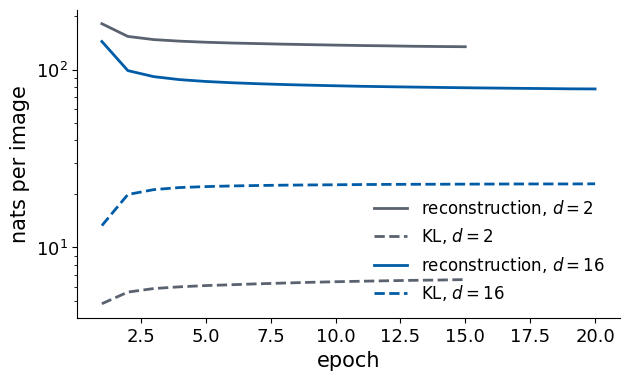

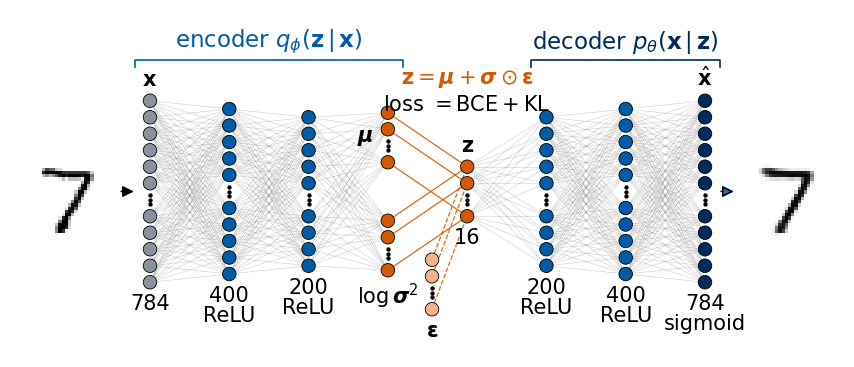

In [18]:
EPOCHS_VAE = 20
t0 = time.time()
print("VAE, d = 2");  vae2, h_vae2 = train(VAE(2, rngs=nnx.Rngs(2)), vae_loss, (Xtr_d,), epochs=15, seed=2)
print("VAE, d = 16"); vae16, h_vae16 = train(VAE(16, rngs=nnx.Rngs(3)), vae_loss, (Xtr_d,), epochs=EPOCHS_VAE, seed=3)
nums["vae_train_seconds"] = time.time() - t0

def test_elbo_terms(model, key=jax.random.key(4)):
    """Loss, reconstruction and KL per test image (one sample of z per image)."""
    _, aux = nnx.jit(vae_loss)(model, (Xte_d,), key)
    return {k: float(v) for k, v in aux.items()}
for name, m in [("vae2", vae2), ("vae16", vae16)]:
    nums[f"{name}_test"] = test_elbo_terms(m)
    print(name, "test, per image:", {k: round(v, 1) for k, v in nums[f"{name}_test"].items()})

fig, ax = plt.subplots(figsize=(7, 4))
for h, lab, col in [(h_vae2, "$d=2$", UJGray), (h_vae16, "$d=16$", UJBlue)]:
    ep = np.arange(1, len(h["loss"]) + 1)
    ax.plot(ep, h["rec"], "-", color=col, label=f"reconstruction, {lab}")
    ax.plot(ep, h["kl"], "--", color=col, label=f"KL, {lab}")
ax.set_xlabel("epoch"); ax.set_ylabel("nats per image"); ax.set_yscale("log"); ax.legend(); plt.show()

# the trained d = 16 VAE with the first test digit and its decoded mean, for the slides
mu0, _ = vae_enc(vae16, Xte_d[:1])
with mpl.rc_context(SLIDE_RC):
    fig = draw_vae([784, 400, 200], 16, [200, 400, 784], x_img=Xte[0].reshape(28, 28),
                   xhat_img=np.asarray(vae_dec(vae16, mu0))[0].reshape(28, 28))
    save(fig, "gen_arch_vae.png"); plt.show()

### 5.3 Tightness of the bound

The ELBO is only a lower bound, so we ask how far it lies below $\log p_\theta(\mathbf x)$ itself. For 200 test images we estimate $\log p_\theta(\mathbf x)$ in two ways, each with $K=1000$ samples. The naive estimate samples the prior, $\log p_\theta(\mathbf x)\approx\log\frac1K\sum_{k}p_\theta(\mathbf x|\mathbf z_k)$ with $\mathbf z_k\sim\mathcal N(0,I)$. The second estimate uses importance sampling with the encoder as proposal: it draws $\mathbf z_k\sim q_\phi(\mathbf z|\mathbf x)$, where the relevant latent vectors are, and corrects for drawing from the wrong distribution with the weights $p(\mathbf z_k)/q_\phi(\mathbf z_k|\mathbf x)$,
$$\log p_\theta(\mathbf x)\approx\log\frac1K\sum_k\frac{p_\theta(\mathbf x|\mathbf z_k)\,p(\mathbf z_k)}{q_\phi(\mathbf z_k|\mathbf x)} .$$

Both sums are unbiased estimates of $p_\theta(\mathbf x)$; their logarithms are lower bounds that tighten as $K$ grows, and for $K=1$ the expectation of the second one is the ELBO [Y. Burda, R. Grosse, R. Salakhutdinov, *Importance Weighted Autoencoders*, [arXiv:1509.00519](https://arxiv.org/abs/1509.00519)]. The sums are computed with `logsumexp`, because the individual $p_\theta(\mathbf x|\mathbf z)$ are as small as $e^{-100}$.

In [19]:
def log_px_estimates(model, X, key, K=1000):
    """Per image: (ELBO with one z, importance-sampling estimate, naive prior-sampling estimate), all in nats."""
    def one_image(x, key):
        k1, k2, k3 = jax.random.split(key, 3)
        mu, lv = model.encode(x[None])                                    # (1, d)
        z_q = mu + jnp.exp(0.5 * lv) * jax.random.normal(k1, (K, mu.shape[1]))   # (K, d) from q(z|x)
        z_p = jax.random.normal(k2, (K, mu.shape[1]))                     # (K, d) from the prior
        log_lik = lambda z: -optax.sigmoid_binary_cross_entropy(model.decode(z), x[None]).sum(-1)   # log p(x|z), (K,)
        log_prior = lambda z: log_normal(z, 0.0, 0.0).sum(-1)
        log_q = log_normal(z_q, mu, lv).sum(-1)
        log_w = log_lik(z_q) + log_prior(z_q) - log_q                     # log importance weights, (K,)
        is_est = jax.scipy.special.logsumexp(log_w) - jnp.log(K)
        naive = jax.scipy.special.logsumexp(log_lik(z_p)) - jnp.log(K)
        elbo = log_lik(reparametrise(mu, lv, k3)).sum() - kl_per_dim(mu, lv).sum()
        return elbo, is_est, naive
    return jax.vmap(one_image)(X, jax.random.split(key, X.shape[0]))

est = nnx.jit(log_px_estimates, static_argnames="K")
parts = [est(vae16, Xte_d[i:i + 20], jax.random.key(30 + i)) for i in range(0, 200, 20)]
elbo_i, is_i, naive_i = [np.concatenate([np.asarray(p[j]) for p in parts]) for j in range(3)]
nums["vae16_bound"] = {"elbo": float(elbo_i.mean()), "log_px_importance": float(is_i.mean()), "log_px_naive": float(naive_i.mean())}
print(f"mean over 200 test images (nats):  ELBO {elbo_i.mean():8.1f}   importance sampling {is_i.mean():8.1f}   naive prior sampling {naive_i.mean():8.1f}")
print(f"gap log p(x) - ELBO, averaged: {np.mean(is_i - elbo_i):.1f} nats")

mean over 200 test images (nats):  ELBO    -98.1   importance sampling    -93.3   naive prior sampling   -154.8
gap log p(x) - ELBO, averaged: 4.8 nats


The importance-sampling estimate, $-93.3$ nats, lies 4.8 nats above the ELBO of $-98.1$ nats: the bound is close to tight. Naive prior sampling gives $-154.8$ nats, a far lower number, although it estimates the same quantity: with $K=1000$ prior samples, almost none lands where $p_\theta(\mathbf x|\mathbf z)$ is large. This is the reason the encoder is needed.

### 5.4 Latent plane as a map

A picture helps to see what the KL term has done to the latent space. Think of the latent plane as a map. The autoencoder puts one pin per image on it: the codes form islands, one or a few per digit, separated by an empty sea, and the decoder was never trained on the sea, which is why the grid points there decoded to nonsense in Section 1. The VAE puts a cloud on the map for every image, a small ellipse of plausible latent vectors centred at $\boldsymbol\mu_\phi(\mathbf x)$ with half-axes $\sigma_{\phi,1}(\mathbf x)$, $\sigma_{\phi,2}(\mathbf x)$. The KL term pulls all clouds towards one standard disc, the region where $\mathcal N(0,I)$ puts its probability, so the clouds of different images overlap and there is no sea left inside the disc. Sampling the model is then like throwing a dart at the disc with the density of $\mathcal N(0,I)$: wherever it lands, it lands inside some cloud, on a part of the map the decoder knows.

The next figure draws this for the two-dimensional models. The left panel shows the autoencoder codes $E(\mathbf x)$ of all test digits (small dots) and, as larger pins, those of three digits per class. The right panel shows, for the VAE with $d=2$, the means $\boldsymbol\mu_\phi(\mathbf x)$ of all test digits (small dots) and the clouds $\boldsymbol\mu_\phi\pm\boldsymbol\sigma_\phi$ of the same three digits per class as ellipses, together with the circles $|\mathbf z|=1,2,3$ of the prior (dotted). The axes of the two panels differ: the autoencoder has chosen its own scale, the VAE the scale of the prior.

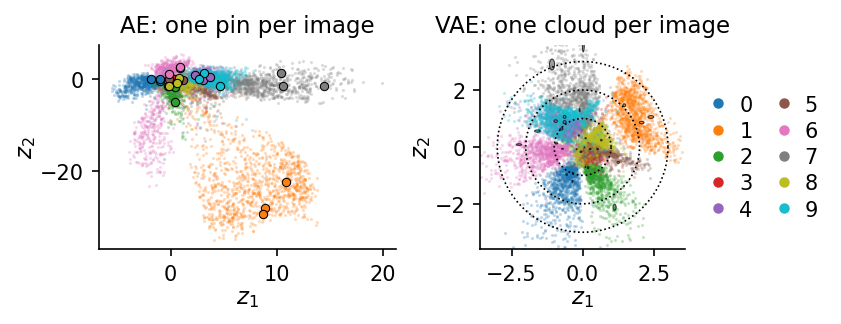

standard deviation of the latent coordinates: AE [3.81 7.46] | VAE means [1.03 1.09]
median width sigma of the VAE clouds: [0.037 0.036]


In [20]:
mu2_te, lv2_te = in_chunks(lambda x: vae_enc(vae2, x), Xte_d)
sig2_te = np.exp(0.5 * lv2_te)
sel = np.concatenate([np.flatnonzero(yte == d)[:3] for d in range(10)])            # three test digits per class
t = np.linspace(0, 2 * np.pi, 200)
with mpl.rc_context(SLIDE_RC):
    fig, (a, b) = plt.subplots(1, 2, figsize=(5.5, 2.05), layout="constrained")
    for d in range(10):
        m = yte == d
        a.scatter(Z_ae2[m, 0], Z_ae2[m, 1], s=0.3, color=cmap10(d), alpha=0.25, rasterized=True)
        b.scatter(mu2_te[m, 0], mu2_te[m, 1], s=0.3, color=cmap10(d), alpha=0.25, rasterized=True)
    for k in sel:
        c = cmap10(yte[k])
        a.plot(*Z_ae2[k], "o", ms=4, mfc=c, mec="k", mew=0.5)
        b.add_patch(Ellipse(mu2_te[k], 2 * sig2_te[k, 0], 2 * sig2_te[k, 1], fc=c, ec="k", lw=0.5, alpha=0.75))
    for r in (1, 2, 3): b.plot(r * np.cos(t), r * np.sin(t), ":", color="k", lw=0.8)
    b.set_xlim(-3.6, 3.6); b.set_ylim(-3.6, 3.6); b.set_aspect("equal")
    a.set_title("AE: one pin per image"); b.set_title("VAE: one cloud per image")
    for ax_ in (a, b): ax_.set_xlabel("$z_1$", labelpad=1); ax_.set_ylabel("$z_2$", labelpad=1)
    handles = [plt.Line2D([], [], ls="", marker="o", ms=4, color=cmap10(d)) for d in range(10)]
    b.legend(handles, [str(d) for d in range(10)], loc="center left", bbox_to_anchor=(1.0, 0.45), handletextpad=0.0,
             labelspacing=0.3, borderaxespad=0.2, ncol=2, columnspacing=0.5)
    save(fig, "gen_vae_latent.png"); plt.show()
nums["vae2_mu_std"] = [float(v) for v in mu2_te.std(0)]
nums["ae2_code_std"] = [float(v) for v in Z_ae2.std(0)]
nums["vae2_sigma_median"] = [float(v) for v in np.median(sig2_te, 0)]
print("standard deviation of the latent coordinates: AE", np.round(Z_ae2.std(0), 2), "| VAE means", np.round(mu2_te.std(0), 2))
print("median width sigma of the VAE clouds:", np.round(np.median(sig2_te, 0), 3))

The autoencoder chooses its own scale and shape: the standard deviations of its two coordinates are 3.8 and 7.5, and its codes form elongated islands with empty space between them. The VAE means have standard deviations close to 1 and fill the disc of radius 2 to 3 of the prior. Each cloud is small, with a median width $\sigma_\phi\approx0.04$ (printed above), because a two-dimensional code must locate an image precisely to reconstruct it; but there are 60 000 training images, and their clouds lie densely side by side across the whole disc, so that the region inside $|\mathbf z|\approx2$ is covered without gaps. Images of the same digit still sit together, because similar images need similar codes to be reconstructed, but the regions of different digits now border on each other instead of being separated by unused space.

### 5.5 Decoded latent grid of the VAE

We now repeat the grid experiment of Section 1 with the VAE, with a figure of the same layout: on the left the latent plane with the means $\boldsymbol\mu_\phi(\mathbf x)$ of the test digits and the grid points, on the right the decoded image of every grid point, with one point and its image marked in red. The decoded image is now the decoder mean $\hat{\mathbf x}=\sigma(G_\theta(\mathbf z))$, the probability of each pixel being black, drawn as grey levels; it is the average of all images that $p_\theta(\mathbf x|\mathbf z)$ could produce at this $\mathbf z$.

The VAE has a prior, and it tells us how to place the grid. We use the quantiles of $\mathcal N(0,1)$ along each axis, $z^{(j)}=\Phi^{-1}\big((j+\tfrac12)/10\big)$, $j=0,\dots,9$, where $\Phi^{-1}$ is the inverse of the cumulative distribution function of the standard normal distribution. The grid values then run from $-1.64$ to $1.64$, densely near the origin and sparsely further out, and every cell of the grid carries the same prior probability, $1/100$. The figure is therefore a picture of what sampling the prior produces: each of the 100 images is equally likely to be the one a random $\mathbf z$ lands near. (The tick labels give the actual, unequally spaced, grid values.)

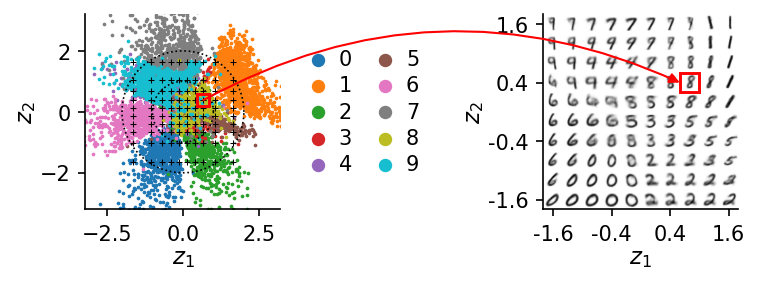

grid values (quantiles of N(0,1)): [-1.64 -1.04 -0.67 -0.39 -0.13  0.13  0.39  0.67  1.04  1.64]


In [21]:
g_q = norm.ppf((np.arange(10) + 0.5) / 10)                                  # quantiles of N(0, 1): equal prior mass per cell
imgs_vae_grid = latent_grid_figure(mu2_te, yte, lambda z: vae_dec(vae2, z), g_q, g_q, highlight=(7, 6),
                                   name="gen_vae_grid.png", prior_circles=True, lim=((-3.2, 3.2), (-3.2, 3.2)))
print("grid values (quantiles of N(0,1)):", np.round(g_q, 2))

Every cell of the VAE grid decodes to a digit-like image, including the cells that lie between the regions of two digits: there the image morphs continuously from one digit into the other, a 7 into a 9, a 0 into a 6. Neighbouring cells are similar, and each digit occupies a connected region, as for the autoencoder, but there are no cells of nonsense, because the KL term has filled the disc of the prior with training clouds. The images are blurry; this is not a defect of the plot but the meaning of the decoder mean, an average of all pixel patterns compatible with $\mathbf z$ (Section 6.2). In two dimensions the plane must hold all ten digits and their styles, so some digits get only a small region (Section 8 counts how often each digit is produced); with $d=16$ the space is roomier, and that is the model we use from now on.

<hr/>
## 6. Sampling a trained VAE

A trained VAE can be used in two different ways, and it is worth keeping them apart. In reconstruction an existing image is encoded, a latent vector is taken from its cloud, and the decoder turns it back into an image: $\mathbf x\to\mathbf z\sim q_\phi(\mathbf z|\mathbf x)\to p_\theta(\mathbf x|\mathbf z)$. In generation there is no input image: $\mathbf z$ is drawn from the prior and decoded, $\mathbf z\sim p(\mathbf z)\to p_\theta(\mathbf x|\mathbf z)$, which draws a sample of $p_\theta(\mathbf x)$ in two steps. The decoder is the same in both cases; only the source of $\mathbf z$ differs. This section looks at both with the $d=16$ VAE, at what exactly is shown when we "show a sample", and at what the samples can and cannot be.

Training and generation use different parts of the network, and the drawing below shows them side by side. In training (left) an image enters the encoder, the two heads give the cloud $(\boldsymbol\mu,\log\boldsymbol\sigma^2)$, the sampling node draws $\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon$, and the decoder returns $\hat{\mathbf x}$; the loss compares $\hat{\mathbf x}$ with $\mathbf x$ (BCE) and the cloud with the prior (KL). For generation (right) the encoder is no longer needed. What we keep after training is the decoder together with the prior: a source of random numbers $\mathbf z\sim\mathcal N(0,I)$ feeds the latent layer directly, and the decoder turns each $\mathbf z$ into a new image. The encoder was a training device: it told the decoder which latent vectors belong to which images, and the KL term made sure that these latent vectors fill the prior, so that the prior can replace the encoder afterwards.

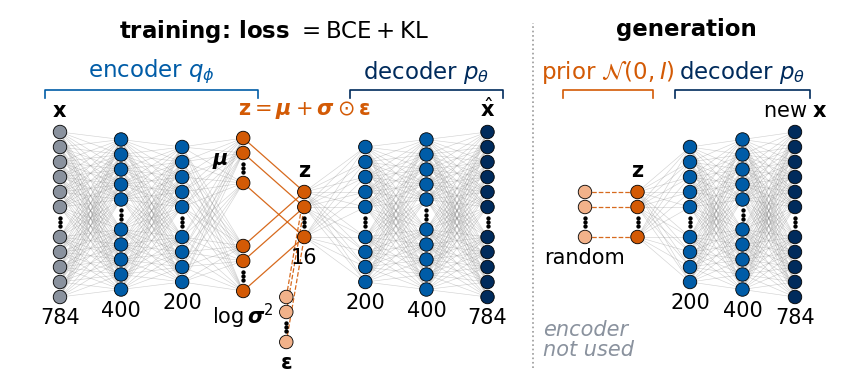

In [22]:
with mpl.rc_context(SLIDE_RC):
    fig = draw_vae_pair([784, 400, 200], 16, [200, 400, 784], size=(5.5, 2.4))
    save(fig, "gen_vae_train_gen.png"); plt.show()

### 6.1 Reconstruction and generation

The figure has four rows. The first row shows one test digit of each class, $\mathbf x$. The second row decodes the centre of its cloud, $\sigma(G_\theta(\boldsymbol\mu_\phi(\mathbf x)))$, and the third a random point of the cloud, $\mathbf z\sim q_\phi(\mathbf z|\mathbf x)$. The fourth row decodes ten latent vectors drawn from the prior $\mathcal N(0,I)$, unrelated to the images above them. All decoded images are decoder means: grey levels are pixel probabilities.

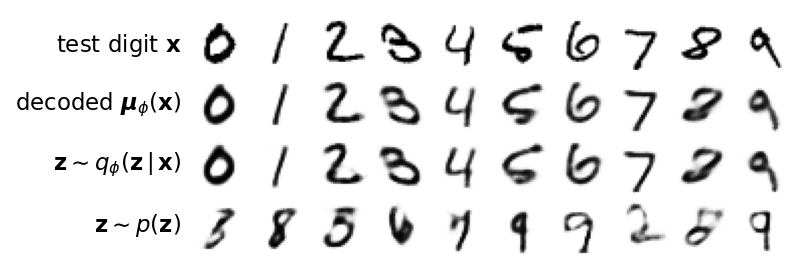

In [23]:
def first_of(digit, k=0): return int(np.flatnonzero(yte == digit)[k])
idx10 = [first_of(d) for d in range(10)]
mu_s, lv_s = vae_enc(vae16, Xte_d[jnp.array(idx10)])
z_q = mu_s + jnp.exp(0.5 * lv_s) * jax.random.normal(jax.random.key(50), mu_s.shape)     # a point of each cloud
z_p = jax.random.normal(jax.random.key(51), (10, 16))                                       # points of the prior
rows = [Xte[idx10], vae_dec(vae16, mu_s), vae_dec(vae16, z_q), vae_dec(vae16, z_p)]
show_grid(np.concatenate([np.asarray(r) for r in rows]), 4, 10, "gen_vae_recon_gen.png", width=5.5, label_width=1.5,
          row_labels=[r"test digit $\mathbf{x}$", r"decoded $\boldsymbol{\mu}_\phi(\mathbf{x})$",
                      r"$\mathbf{z}\sim q_\phi(\mathbf{z}\,|\,\mathbf{x})$", r"$\mathbf{z}\sim p(\mathbf{z})$"])

The reconstructions keep the identity and most of the style of the input, slightly smoothed: sixteen numbers cannot hold every detail of 784 pixels. The centre of the cloud and a random point of it decode to nearly the same image, because the clouds are small. The generated digits in the last row belong to no input; they are what the model believes a typical digit looks like at ten random places of the prior. Most are clear digits, some are less clear, lying between two digits, and they are as blurry as the reconstructions.

### 6.2 Decoder mean and decoder samples

The decoder does not output an image but a distribution of images, $p_\theta(\mathbf x|\mathbf z)=\prod_j\hat x_j^{x_j}(1-\hat x_j)^{1-x_j}$. What is usually shown, and what we have shown so far, is its mean $\hat{\mathbf x}=\sigma(G_\theta(\mathbf z))$, the probability of every pixel being black, as a grey level. A sample of the model is something else: every pixel is drawn independently, black with probability $\hat x_j$ and white otherwise. The next figure shows ten decoder means (first row), one Bernoulli sample of each (second row) and a second, independent sample (third row). The fourth row shows, for each mean, the training image closest to it in Euclidean distance $\lVert\hat{\mathbf x}-\mathbf x_i\rVert$, to check whether the generator merely recalls its training data.

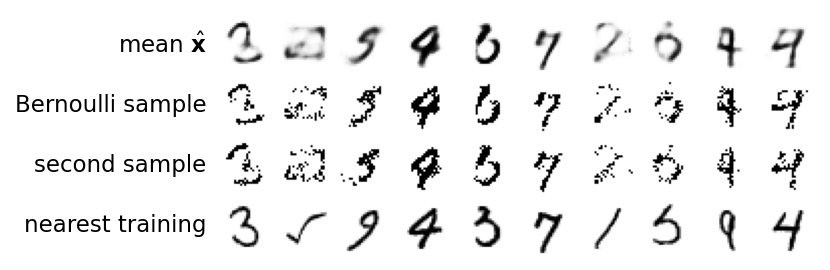

mean distance to the nearest training image: generated 4.48, real test digits 4.19


In [24]:
@jax.jit
def nn_dist(A, B):
    """Distance of every row of A to its nearest row of B, and the index of that row."""
    d2 = (A ** 2).sum(1)[:, None] - 2 * A @ B.T + (B ** 2).sum(1)[None, :]
    return jnp.sqrt(jnp.maximum(d2.min(1), 0)), d2.argmin(1)

x_mean = vae_dec(vae16, jax.random.normal(jax.random.key(52), (10, 16)))       # decoder means of 10 prior samples
x_s1 = jax.random.bernoulli(jax.random.key(53), x_mean).astype(jnp.float32)     # every pixel drawn independently
x_s2 = jax.random.bernoulli(jax.random.key(54), x_mean).astype(jnp.float32)
_, i_nn = nn_dist(x_mean, Xtr_d)
show_grid(np.concatenate([np.asarray(x_mean), np.asarray(x_s1), np.asarray(x_s2), Xtr[np.asarray(i_nn)]]), 4, 10,
          "gen_vae_mean_sample.png", width=5.5, label_width=1.5,
          row_labels=[r"mean $\hat{\mathbf{x}}$", "Bernoulli sample", "second sample", "nearest training"])

z_new = jax.random.normal(jax.random.key(11), (10000, 16))
vae16_samples = in_chunks(lambda z: vae_dec(vae16, z), z_new)                  # 10 000 generated decoder means
d_gen = np.asarray(nn_dist(jnp.asarray(vae16_samples[:500]), Xtr_d)[0])
d_test = np.asarray(nn_dist(Xte_d[:500], Xtr_d)[0])
nums["vae_nn_dist_generated"], nums["vae_nn_dist_test"] = float(d_gen.mean()), float(d_test.mean())
print(f"mean distance to the nearest training image: generated {d_gen.mean():.2f}, real test digits {d_test.mean():.2f}")

The mean is smooth and blurry, the samples are sharp but speckled: inside the strokes, where $\hat x_j$ is close to 1, nearly every pixel comes out black; at the edges of the strokes, where $\hat x_j$ is around $\tfrac12$, the pixels are black or white at random, and two samples of the same mean differ there. The speckle is the correct output of a model that treats the pixels as independent given $\mathbf z$: all correlations between pixels, such as the continuity of a stroke, must be carried by $\mathbf z$, and what $\mathbf z$ does not fix is filled in by independent coin flips. This is why images from a Bernoulli VAE are shown as means, and it is the same mechanism that will matter for spin configurations in Lab 025, where every spin is drawn independently given $\mathbf z$ and "showing the mean" is not an option.

The nearest training images share the rough shape of the generated means but differ in the details, and for the less clear means even in the digit. The distances confirm this for 500 generated means: they lie on average 4.48 from the nearest of the 60 000 training images, while real test digits, which the network never saw, lie at 4.19. The generated digits are no closer to the training set than genuinely new digits. A VAE sample is a new combination of features learned from the data (a slant from here, a loop from there), not a copy; it is also not more than that: it cannot contain a kind of digit, or a stroke style, that the training set does not contain.

### 6.3 Aggregate posterior and prior

Generation works as well as the prior region is covered by encoded data. The distribution of latent vectors that the data actually occupy is the aggregate posterior,
$$q_\phi(\mathbf z)=\frac1n\sum_{i=1}^{n}q_\phi(\mathbf z\,|\,\mathbf x_i),$$
the average of the clouds of all images, which we sample by encoding a test image and drawing one point of its cloud. The KL term pulls every cloud towards the prior, but it cannot make $q_\phi(\mathbf z)$ equal to $p(\mathbf z)$ exactly: the clouds must stay distinguishable to reconstruct the images. Where the prior puts probability that the aggregate posterior does not, there are prior holes, regions that generation visits but no training image was encoded into, and the decoder there produces the less clear images seen in Section 6.1.

The left panel of the next figure projects 10 000 samples of each distribution onto the two most used latent coordinates (those with the largest KL term, Section 7): the aggregate posterior (blue) against the prior (grey), with the circles $|\mathbf z|=1,2,3$. In 16 dimensions most of the probability of $\mathcal N(0,I)$ lies on a thin shell of radius about $\sqrt{16}=4$, so the right panel compares the distributions of the length $|\mathbf z|$: a histogram for the aggregate posterior, and for the prior both a histogram and the exact chi distribution with 16 degrees of freedom. Finally, we measure the holes directly. For every prior sample we compute the distance to the nearest of 10 000 encoded test points, and compare it with the same distance for a second, independent set of encoded test points; prior samples that land in holes are farther from the encoded data than encoded data are from each other.

standard deviation of the aggregate posterior per coordinate: [0.98 0.97 0.97 0.97 1.02 1.   0.99 1.04 1.01 1.02 1.   1.01 1.   1.04
 1.04 1.04]
mean |z|: aggregate posterior 4.01, prior 3.93;  median distance to the nearest encoded test point: from prior samples 2.61, from encoded points 1.55


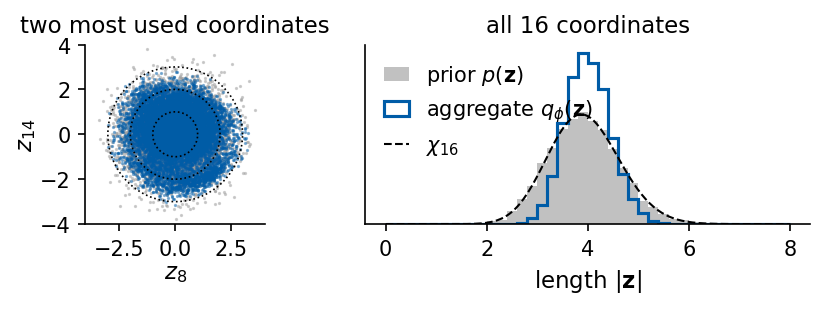

In [25]:
mu16_te, lv16_te = in_chunks(lambda x: vae_enc(vae16, x), Xte_d)
kl_dims = np.asarray(kl_per_dim(mu16_te, lv16_te)).mean(0)             # mean KL of every latent coordinate
order = np.argsort(kl_dims)[::-1]                                       # most used coordinates first
z_agg = mu16_te + np.exp(0.5 * lv16_te) * np.asarray(jax.random.normal(jax.random.key(55), mu16_te.shape))
z_agg2 = mu16_te + np.exp(0.5 * lv16_te) * np.asarray(jax.random.normal(jax.random.key(56), mu16_te.shape))
z_pri = np.asarray(jax.random.normal(jax.random.key(57), mu16_te.shape))
r_agg, r_pri = np.linalg.norm(z_agg, axis=1), np.linalg.norm(z_pri, axis=1)
d_hole_prior = np.asarray(nn_dist(jnp.asarray(z_pri), jnp.asarray(z_agg))[0])   # prior sample -> nearest encoded point
d_hole_data = np.asarray(nn_dist(jnp.asarray(z_agg2), jnp.asarray(z_agg))[0])   # encoded point -> nearest other encoded point
agg_std = np.sqrt(mu16_te.var(0) + np.exp(lv16_te).mean(0))           # standard deviation of q(z) per coordinate
nums["aggpost"] = {"radius_mean_q": float(r_agg.mean()), "radius_mean_prior": float(r_pri.mean()),
                   "std_min": float(agg_std.min()), "std_max": float(agg_std.max()),
                   "nn_prior_median": float(np.median(d_hole_prior)), "nn_data_median": float(np.median(d_hole_data))}
print("standard deviation of the aggregate posterior per coordinate:", np.round(agg_std, 2))
print(f"mean |z|: aggregate posterior {r_agg.mean():.2f}, prior {r_pri.mean():.2f};  median distance to the nearest "
      f"encoded test point: from prior samples {np.median(d_hole_prior):.2f}, from encoded points {np.median(d_hole_data):.2f}")

k1_, k2_ = order[0], order[1]
with mpl.rc_context(SLIDE_RC):
    fig, (a, b) = plt.subplots(1, 2, figsize=(5.5, 1.95), layout="constrained", gridspec_kw=dict(width_ratios=[1, 1.25]))
    a.scatter(z_pri[:, k1_], z_pri[:, k2_], s=0.3, color="0.6", alpha=0.5, rasterized=True, label=r"prior $p(\mathbf{z})$")
    a.scatter(z_agg[:, k1_], z_agg[:, k2_], s=0.3, color=UJBlue, alpha=0.5, rasterized=True, label=r"$q_\phi(\mathbf{z})$")
    for r in (1, 2, 3): a.plot(r * np.cos(t), r * np.sin(t), ":", color="k", lw=0.8)
    a.set_xlim(-4, 4); a.set_ylim(-4, 4); a.set_aspect("equal")
    a.set_xlabel(f"$z_{{{k1_ + 1}}}$", labelpad=1); a.set_ylabel(f"$z_{{{k2_ + 1}}}$", labelpad=1)
    a.set_title("two most used coordinates")
    bins = np.linspace(0, 8, 41)
    b.hist(r_pri, bins, density=True, color="0.6", alpha=0.6, label=r"prior $p(\mathbf{z})$")
    b.hist(r_agg, bins, density=True, histtype="step", color=UJBlue, lw=1.5, label=r"aggregate $q_\phi(\mathbf{z})$")
    rr = np.linspace(0, 8, 200); b.plot(rr, chi.pdf(rr, 16), "k--", lw=1.0, label=r"$\chi_{16}$")
    b.set_xlabel(r"length $|\mathbf{z}|$"); b.set_yticks([]); b.set_title("all 16 coordinates")
    b.legend(loc="upper left", handlelength=1.2)
    save(fig, "gen_vae_aggpost.png"); plt.show()

In the projection the aggregate posterior looks like the prior: a round cloud with the right spread, without visible holes. The coordinate-wise standard deviations of $q_\phi(\mathbf z)$ printed above are close to 1, as the KL term demands. The lengths tell a more careful story. Both distributions peak near $|\mathbf z|\approx4$, the shell where 16-dimensional Gaussian probability lives, but they do not coincide, and the hole measurement shows that a point drawn from the prior is typically farther from the nearest encoded test image than an encoded point is from its neighbours (median distances printed above). The prior and the aggregate posterior agree in their low-dimensional summaries but differ in the details of the 16-dimensional shape: part of what the prior proposes lies off the encoded data. This is the reason why generated images are, on average, less clear than reconstructions, which Section 8 will quantify with a classifier.

### 6.4 Interpolation between two digits

A well-shaped latent space should also connect digits smoothly. We encode two test digits, $\boldsymbol\mu_a=\boldsymbol\mu_\phi(\mathbf x_a)$ and $\boldsymbol\mu_b=\boldsymbol\mu_\phi(\mathbf x_b)$, and decode the straight line $\mathbf z(t)=(1-t)\boldsymbol\mu_a+t\boldsymbol\mu_b$, $t\in[0,1]$. For comparison, the last row cross-fades the pixels, $(1-t)\mathbf x_a+t\mathbf x_b$, for the first pair.

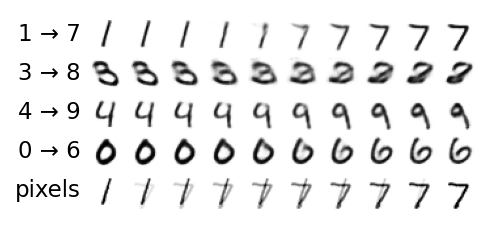

In [26]:
pairs = [(first_of(1), first_of(7)), (first_of(3), first_of(8)), (first_of(4), first_of(9)), (first_of(0), first_of(6))]
ts = np.linspace(0, 1, 10)[:, None]
rows = []
for a_, b_ in pairs:
    mu_ab, _ = vae_enc(vae16, Xte_d[jnp.array([a_, b_])])
    rows.append(np.asarray(vae_dec(vae16, (1 - ts) * mu_ab[0] + ts * mu_ab[1])))
a_, b_ = pairs[0]
rows.append((1 - ts) * Xte[a_] + ts * Xte[b_])
labels = [f"{yte[a_]} → {yte[b_]}" for a_, b_ in pairs] + ["pixels"]
show_grid(np.concatenate(rows), len(rows), 10, "gen_vae_interp.png", width=3.2, label_width=0.6, row_labels=labels)

Every point of the latent line decodes to a plausible digit: a 1 is bent into a 7, a 4 is closed into a 9. The pixel cross-fade passes through images that are two superposed digits, no digit at all. The latent space is a coordinate system in which straight lines stay among the data, which is the property that the prior coverage of Section 6.3 provides along the line.

<hr/>
## 7. Latent coordinates and disentanglement

The latent vector of the $d=16$ VAE has sixteen coordinates. Two questions about them matter for using the model: which coordinates are used at all, and what each of them does to the image.

The first is answered by the KL term of coordinate $k$, averaged over the test images,
$$\overline{\mathrm{KL}}_k=\big\langle\tfrac12(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1)\big\rangle_{\mathbf x},$$
the information, in nats, that coordinate $k$ carries about the image. A value $\overline{\mathrm{KL}}_k\approx0$ would mean $q(z_k|\mathbf x)=\mathcal N(0,1)$ for every image: a coordinate ignored by the decoder. Coordinates with $\overline{\mathrm{KL}}_k>0.1$ nats are called active.

The second is answered by latent traversals. We start from the encoding $\boldsymbol\mu_\phi(\mathbf x)$ of one test digit, change one coordinate $z_k$ while keeping the others, and decode. To go beyond looking, we also measure two properties of every decoded image $\hat{\mathbf x}$, treated as a distribution of ink over the pixel positions $(u,v)$ (column $u$, row $v$ counted downwards): the slant $-\mathrm{Cov}(u,v)/\mathrm{Var}(v)$, the horizontal shift of the ink per row (positive when the digit leans to the right), and the ink, the mean pixel value, which grows with the stroke thickness and the size of the digit. For 300 test digits and every coordinate $k$ we decode $z_k=-2$ and $z_k=+2$ and record the change of both properties, $|\Delta\,\text{slant}|$ and $|\Delta\,\text{ink}|$, averaged over the digits and divided by the standard deviation of the property over the real test digits. A coordinate that controlled one property only would show a large change in one and none in the other.

KL per latent coordinate, sorted (nats): [2.23 2.15 2.14 1.71 1.7  1.53 1.49 1.48 1.36 1.32 1.15 1.12 1.   0.98
 0.68 0.65]
coordinates with KL > 0.1 nats: 16 of 16


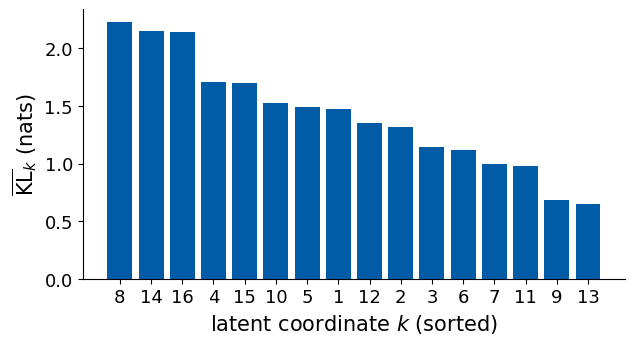

|Delta slant| / std: [0.44 0.2  0.3  0.91 0.28 0.2  0.28 2.38 0.12 0.37 0.17 0.19 0.08 0.42
 0.35 1.28]
|Delta ink|   / std: [0.93 0.47 0.34 1.17 0.78 0.19 0.12 1.5  0.13 0.26 0.14 0.66 0.15 1.79
 0.64 1.38]
coordinates changing both properties by more than 0.3 standard deviations: 7 of 16


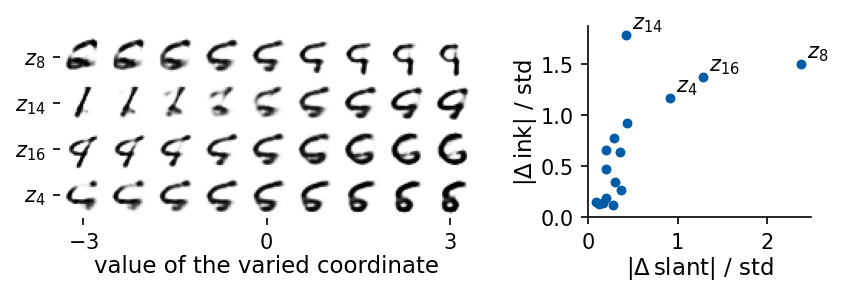

In [27]:
kl_vals = kl_dims                                                      # computed in Section 6.3
nums["vae16_kl_per_dim_sorted"] = [float(v) for v in kl_vals[order]]
nums["vae16_active_dims"] = int((kl_vals > 0.1).sum())
print("KL per latent coordinate, sorted (nats):", np.round(kl_vals[order], 2))
print("coordinates with KL > 0.1 nats:", nums["vae16_active_dims"], "of 16")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(np.arange(16), kl_vals[order], color=UJBlue)
ax.set_xticks(np.arange(16)); ax.set_xticklabels([str(k + 1) for k in order])
ax.set_xlabel("latent coordinate $k$ (sorted)"); ax.set_ylabel(r"$\overline{\mathrm{KL}}_k$ (nats)"); plt.show()

def shape_features(imgs):
    """Slant -Cov(u, v)/Var(v) and ink (mean pixel value) of images (n, 784), treated as ink distributions."""
    I = np.asarray(imgs).reshape(-1, 28, 28)
    v, u = np.mgrid[0:28, 0:28]                                    # v: row (downwards), u: column
    w = I.sum((1, 2))
    ub, vb = (I * u).sum((1, 2)) / w, (I * v).sum((1, 2)) / w
    cuv = (I * (u - ub[:, None, None]) * (v - vb[:, None, None])).sum((1, 2)) / w
    cvv = (I * (v - vb[:, None, None]) ** 2).sum((1, 2)) / w
    return -cuv / cvv, w / 784

slant_te, ink_te = shape_features(Xte)
base = mu16_te[:300]                                                # encodings of 300 test digits
d_slant, d_ink = np.zeros(16), np.zeros(16)
for k in range(16):
    zm, zp = base.copy(), base.copy(); zm[:, k] = -2.0; zp[:, k] = 2.0
    sm, im_ = shape_features(vae_dec(vae16, jnp.asarray(zm))); sp_, ip_ = shape_features(vae_dec(vae16, jnp.asarray(zp)))
    d_slant[k] = np.abs(sp_ - sm).mean() / slant_te.std()
    d_ink[k] = np.abs(ip_ - im_).mean() / ink_te.std()
nums["traversal_dslant"], nums["traversal_dink"] = d_slant.tolist(), d_ink.tolist()
both = int(((d_slant > 0.3) & (d_ink > 0.3)).sum())
nums["traversal_both_03"] = both
print("|Delta slant| / std:", np.round(d_slant, 2)); print("|Delta ink|   / std:", np.round(d_ink, 2))
print(f"coordinates changing both properties by more than 0.3 standard deviations: {both} of 16")

k_base = first_of(5)
vals = np.linspace(-3, 3, 9)
show_dims = list(order[:4])                                         # the four most used coordinates
rows = []
for k in show_dims:
    Zt = np.repeat(np.asarray(mu16_te[k_base])[None], len(vals), 0); Zt[:, k] = vals
    rows.append(np.asarray(vae_dec(vae16, jnp.asarray(Zt))))
nums["traversal_dims"] = [int(k + 1) for k in show_dims]
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 1.9))
    a = fig.add_axes([0.07, 0.17, 0.5, 0.7])
    a.imshow(mosaic(np.concatenate(rows), 4, 9), cmap="gray_r", vmin=0, vmax=1, extent=(-0.5, 8.5, 3.5, -0.5))
    a.set_yticks(range(4)); a.set_yticklabels([f"$z_{{{k + 1}}}$" for k in show_dims])
    a.set_xticks([0, 4, 8]); a.set_xticklabels(["$-3$", "0", "$3$"]); a.set_xlabel("value of the varied coordinate", labelpad=1)
    for s_ in a.spines.values(): s_.set_visible(False)
    b = fig.add_axes([0.71, 0.2, 0.27, 0.67])
    b.scatter(d_slant, d_ink, s=14, color=UJBlue)
    for k in show_dims:
        b.annotate(f"$z_{{{k + 1}}}$", (d_slant[k], d_ink[k]), xytext=(3, 3), textcoords="offset points", fontsize=10)
    b.set_xlabel(r"$|\Delta\,$slant$|$ / std", labelpad=1); b.set_ylabel(r"$|\Delta\,$ink$|$ / std", labelpad=1)
    b.set_xlim(left=0); b.set_ylim(bottom=0)
    save(fig, "gen_vae_traversal.png"); plt.show()

All 16 coordinates carry information, but unequally: the largest $\overline{\mathrm{KL}}_k$ is about three times the smallest (values printed above). The traversals of the four most used coordinates, for one test 5, show continuous changes of the digit, and each row changes several things at once: the slant together with the width, the thickness together with the size, and often the identity of the digit as well. The measurement confirms what the eye sees. Each of the four most used coordinates changes both the slant and the ink by more than 0.4 standard deviations, and so do several of the others (the number of coordinates that change both by more than 0.3 standard deviations is printed above); no coordinate is a pure "slant knob" or a pure "thickness knob".

There is a reason for this, and it is built into the loss. The prior $\mathcal N(0,I)$ and the KL term are unchanged by any rotation $\mathbf z\to R\mathbf z$ of the latent space, and the decoder can absorb the rotation, $G'(\mathbf z)=G(R^\top\mathbf z)$, so the ELBO does not single out any particular set of axes. A rotated latent space, in which every axis mixes slant, thickness and identity, is as good for the ELBO as one in which they are separated.

For many purposes we would like the opposite. A latent representation is called disentangled when each coordinate corresponds to one distinct, independent property of the data (one factor of variation): one coordinate for the slant, one for the thickness, one for the size. Such a representation can be read (the value of $z_3$ is the slant), controlled (change only the thickness), and, in physics, it can discover the relevant variables of a system, for instance a coordinate that is the magnetisation of a spin configuration. Without labels or further assumptions disentanglement cannot be guaranteed [F. Locatello *et al.*, *Challenging Common Assumptions in the Unsupervised Learning of Disentangled Representations*, ICML 2019, [PMLR 97, 4114](https://proceedings.mlr.press/v97/locatello19a.html)], but it can be encouraged. The $\beta$-VAE of Lab 026 multiplies the KL term by a factor $\beta>1$, which makes information in $\mathbf z$ more expensive and pushes the encoder towards the factorised prior $\prod_k\mathcal N(0,1)$, so that the coordinates tend to carry independent factors. Here we follow a different route, for the case in which the factor we care about is known and labelled: the conditional VAE of Section 9 is told the digit, and its latent vector is left to carry everything else.

Exercises:

1. Train VAEs with $d=32$ and $d=64$ and plot $\overline{\mathrm{KL}}_k$. Do all coordinates stay in use?
2. Train the $d=16$ VAE without the KL term (loss = reconstruction only) and generate from $\mathcal N(0,I)$ again. What happens, and why? Then multiply the KL term by $\beta=4$: what happens to the number of active coordinates, to the sharpness of the samples, and to the traversal measurement above?

<hr/>
## 8. Classifier as referee

So far the generated images have been judged by eye. To measure what a generator produces we need a referee: a classifier trained on the real data, whose accuracy on real test data we know. We then apply it, unchanged, to synthetic images.

The classifier is a small convolutional neural network (CNN): two convolutions ($3\times3$, 16 and 32 channels, ReLU), each followed by $2\times2$ max-pooling ($28\to14\to7$), a dense layer of 128 units and 10 outputs $f_c(\mathbf x)$. It is trained by minimising the cross-entropy
$$\mathcal L=-\frac1n\sum_{i}\log p(y_i|\mathbf x_i),\qquad p(c|\mathbf x)=\frac{e^{f_c(\mathbf x)}}{\sum_{c'}e^{f_{c'}(\mathbf x)}},$$
which is the negative log-likelihood of the labels (Section 2); $p(c|\mathbf x)$ is the probability the network assigns to digit $c$, and $\max_cp(c|\mathbf x)$ is its confidence.

A convolution is a dense layer applied to every patch of the image. A $3\times3$ convolution with $C_{\rm in}$ input and $C_{\rm out}$ output channels computes, at every pixel, the same linear map of the $9C_{\rm in}$ numbers in the $3\times3$ neighbourhood, plus a bias. The implementation follows this description literally: `patches3x3` collects the neighbourhoods, $(B,H,W,C_{\rm in})\to(B,H,W,9C_{\rm in})$, and an ordinary `nnx.Linear(9 C_in, C_out)` acts on the last axis. This "im2col" (image to columns) form turns the convolution into one large matrix product, which on a CPU runs several times faster than a direct convolution for these small filters. The weights are shared over all positions, exactly as in a convolution.

For a minibatch of $B$ images the shapes are $(B,784)\to$ reshape $(B,28,28,1)\to$ patches $(B,28,28,9)\to$ conv $(B,28,28,16)\to$ pool $(B,14,14,16)\to$ patches $(B,14,14,144)\to$ conv $(B,14,14,32)\to$ pool $(B,7,7,32)\to$ flatten $(B,1568)\to(B,128)\to$ logits $(B,10)$. Zero padding at the border (`"SAME"`) keeps the image size. Max-pooling over $2\times2$ blocks is a reshape: the axis of length 28 is split into $(14,2)$, and the maximum is taken over the axes of length 2. After four epochs the classifier reaches an accuracy of 0.9854 on the 10 000 real test digits, which sets the baseline for everything that follows.

In [28]:
def patches3x3(h):
    """All 3x3 neighbourhoods of every pixel (zero padding at the border).
    (B, H, W, C) -> (B, H, W, 9 C): the 9 C numbers a 3x3 filter sees at each position."""
    return jax.lax.conv_general_dilated_patches(h, filter_shape=(3, 3), window_strides=(1, 1), padding="SAME",
                                                dimension_numbers=("NHWC", "HWIO", "NHWC"))

def maxpool2x2(h):
    """(B, H, W, C) -> (B, H/2, W/2, C): maximum over non-overlapping 2x2 blocks."""
    B, H, W, C = h.shape
    return h.reshape(B, H // 2, 2, W // 2, 2, C).max(axis=(2, 4))

class CNN(nnx.Module):
    """conv(3x3, 16) - ReLU - pool - conv(3x3, 32) - ReLU - pool - dense 128 - ReLU - dense 10."""
    def __init__(self, *, rngs):
        self.conv1 = nnx.Linear(9 * 1, 16, rngs=rngs)       # a 3x3 convolution = one dense layer applied to every 3x3 patch
        self.conv2 = nnx.Linear(9 * 16, 32, rngs=rngs)
        self.f1, self.f2 = nnx.Linear(7 * 7 * 32, 128, rngs=rngs), nnx.Linear(128, 10, rngs=rngs)
    def __call__(self, x):                                   # x: (B, 784) -> logits (B, 10)
        B = x.shape[0]
        h = x.reshape(B, 28, 28, 1)                          # layout (batch, height, width, channels)
        h = maxpool2x2(nnx.relu(self.conv1(patches3x3(h))))  # (B, 28, 28, 9) -> (B, 28, 28, 16) -> (B, 14, 14, 16)
        h = maxpool2x2(nnx.relu(self.conv2(patches3x3(h))))  # (B, 14, 14, 144) -> (B, 14, 14, 32) -> (B, 7, 7, 32)
        return self.f2(nnx.relu(self.f1(h.reshape(B, -1))))  # (B, 1568) -> (B, 128) -> (B, 10)

def clf_loss(model, batch, key):
    x, y = batch
    logits = model(x)
    loss = optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()
    return loss, {"loss": loss, "acc": jnp.mean(logits.argmax(-1) == y)}

assert patches3x3(jnp.zeros((2, 28, 28, 1))).shape == (2, 28, 28, 9)
assert CNN(rngs=nnx.Rngs(0))(Xtr_d[:3]).shape == (3, 10)
print("CNN classifier"); clf, _ = train(CNN(rngs=nnx.Rngs(5)), clf_loss, (Xtr_d, ytr_d), epochs=4, seed=5, batch_size=256, log_every=1)
clf_prob = nnx.jit(lambda m, x: jax.nn.softmax(m(x)))
def classify(X):
    """Probabilities p(c | x) of the classifier for every image."""
    return in_chunks(lambda x: clf_prob(clf, x), jnp.asarray(X))
P_test = classify(Xte)
nums["clf_test_acc"] = float((P_test.argmax(1) == yte).mean())
print(f"classifier accuracy on the 10 000 real test digits: {nums['clf_test_acc']:.4f}")

CNN classifier


  epoch   1: acc 0.9096  loss 0.3065   ( 18.3 s)


  epoch   2: acc 0.9749  loss 0.0825   ( 38.4 s)


  epoch   3: acc 0.9825  loss 0.0573   ( 56.1 s)


  epoch   4: acc 0.9862  loss 0.0449   ( 69.2 s)


classifier accuracy on the 10 000 real test digits: 0.9854


### Confusion matrices of reconstructions

A confusion matrix has one row per true digit $a$ and one column per digit $b$ assigned by the classifier:
$$C_{ab}=\frac{\#\{\text{images of digit }a\text{ assigned to }b\}}{\#\{\text{images of digit }a\}},\qquad\sum_bC_{ab}=1 .$$
A perfect generator-plus-classifier gives the identity matrix, and the mean of the diagonal, $\frac1{10}\mathrm{tr}\,C$, is the fraction of correctly classified images averaged over the digits. An unconditional VAE is not told which digit to draw, so we take the digit from its input: each real test digit $\mathbf x$ of label $a$ is encoded, one $\mathbf z\sim q_\phi(\mathbf z|\mathbf x)$ is drawn, and the classifier labels the decoded image $\hat{\mathbf x}=\sigma(G_\theta(\mathbf z))$. This tests reconstruction, Section 6.1, in numbers. The figure shows the matrix for $d=2$; the printout gives the mean diagonal for the real test images (the baseline) and for both VAEs.

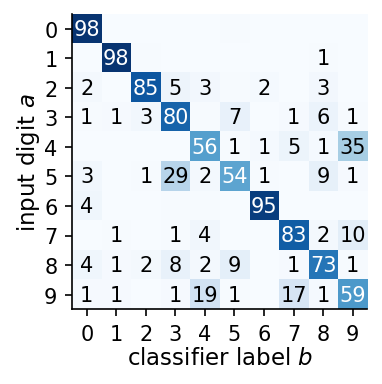

{'real': 0.985, 'vae2': 0.783, 'vae16': 0.953}
largest off-diagonal entry, d = 2: 4 -> 9: 0.346


In [29]:
def vae_recon_sample(model, X, key):
    mu, lv = in_chunks(lambda x: vae_enc(model, x), jnp.asarray(X))
    z = mu + np.exp(0.5 * lv) * np.asarray(jax.random.normal(key, mu.shape))
    return in_chunks(lambda z: vae_dec(model, z), jnp.asarray(z))

def confusion(true, pred):
    """C[a, b] = fraction of the samples with row label a (true or requested digit) that the classifier assigns to b."""
    C = np.zeros((10, 10))
    np.add.at(C, (true, pred), 1)
    return C / C.sum(1, keepdims=True)

def plot_confusion(ax, C, ylabel):
    """Confusion matrix in %, entries of at least 1 % written in the cells."""
    ax.imshow(C, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            if round(100 * C[i, j]) >= 1:
                ax.text(j, i, f"{100 * C[i, j]:.0f}", ha="center", va="center", fontsize=10,
                        color="white" if C[i, j] > 0.5 else "black")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("classifier label $b$", labelpad=1); ax.set_ylabel(ylabel, labelpad=1)

rec2 = vae_recon_sample(vae2, Xte, jax.random.key(20))
rec16 = vae_recon_sample(vae16, Xte, jax.random.key(21))
mats = {"real": confusion(yte, P_test.argmax(1)), "vae2": confusion(yte, classify(rec2).argmax(1)),
        "vae16": confusion(yte, classify(rec16).argmax(1))}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.5, 2.45), layout="constrained")
    plot_confusion(ax, mats["vae2"], "input digit $a$")
    save(fig, "gen_vae_confusion.png"); plt.show()
nums["confusion_diag_mean"] = {k: float(np.trace(C) / 10) for k, C in mats.items()}
C2 = mats["vae2"].copy(); np.fill_diagonal(C2, 0)
i, j = np.unravel_index(np.argmax(C2), C2.shape)
nums["vae2_worst_confusion"] = [int(i), int(j), float(C2[i, j])]
print({k: round(v, 3) for k, v in nums["confusion_diag_mean"].items()})
print(f"largest off-diagonal entry, d = 2: {i} -> {j}: {C2[i, j]:.3f}")

With $d=16$ the decoded digits keep their identity almost as often as the classifier recognises the real images (mean diagonal 0.953 against 0.985). With $d=2$ the latent plane is too small (mean diagonal 0.783): digits that look alike, such as 4 and 9 or 3, 5 and 8, share a region of the plane, and the decoder produces the wrong one; the worst case is a 4 classified as a 9 in 35% of the reconstructions.

### Digit distribution of generated samples

Now the images are decoded from the prior, $\mathbf z\sim\mathcal N(0,I)$, with no input digit, which is how the VAE is used as a generator. We measure two things. The first is the class distribution of 10 000 generated digits, $f_b=\#\{\text{samples assigned to }b\}/N$, which we compare with the fraction of each digit in the training set; a missing class would show up here. The second is the confidence of the classifier, $\max_c p(c|\hat{\mathbf x})$. We report the fraction of images with confidence above 0.9 and compare real test digits, VAE reconstructions ($\mathbf z\sim q_\phi(\mathbf z|\mathbf x)$, Section 6.1), VAE samples ($\mathbf z\sim\mathcal N(0,I)$), and the random decodings of the autoencoder of Section 1 (for $d=2$ uniform on the grid box, for $d=16$ $z_k\sim\mathcal N(m_k,s_k^2)$).

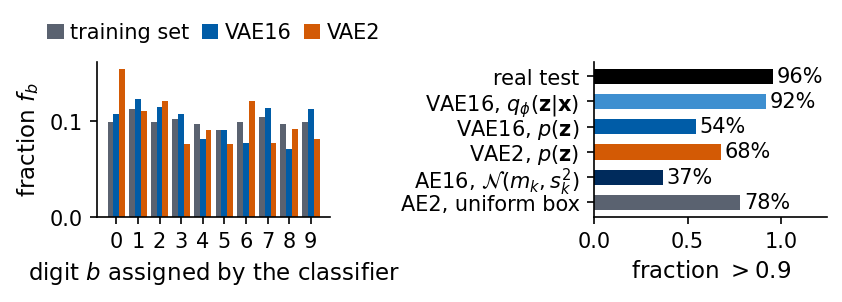

real_test            confident (> 0.9): 0.959
vae16_recon          confident (> 0.9): 0.922
vae16_prior          confident (> 0.9): 0.545
vae2_prior           confident (> 0.9): 0.680
ae16_fitted_gauss    confident (> 0.9): 0.367
ae2_box              confident (> 0.9): 0.781
class fractions, training set:           [0.099 0.112 0.099 0.102 0.097 0.09  0.099 0.104 0.098 0.099]
class fractions, VAE d = 16:             [0.107 0.123 0.115 0.107 0.082 0.091 0.077 0.114 0.071 0.112]
class fractions, VAE d = 2:              [0.154 0.111 0.122 0.076 0.09  0.076 0.121 0.077 0.092 0.081]
class fractions, AE d = 2, uniform box:  [0.052 0.476 0.028 0.004 0.011 0.072 0.202 0.117 0.004 0.034]


In [30]:
z2_new = jax.random.normal(jax.random.key(12), (10000, 2))
vae2_samples = in_chunks(lambda z: vae_dec(vae2, z), z2_new)
z_box = lo + (hi - lo) * np.asarray(jax.random.uniform(jax.random.key(13), (2000, 2)))
ae2_box_samples = np.asarray(ae_decode(ae2, jnp.asarray(z_box, dtype=jnp.float32)))

P_vae16, P_vae2 = classify(vae16_samples), classify(vae2_samples)
P_ae16, P_ae2, P_rec16 = classify(imgs_ae16_fit), classify(ae2_box_samples), classify(rec16)
f_train = np.bincount(ytr, minlength=10) / len(ytr)
f16, f2 = np.bincount(P_vae16.argmax(1), minlength=10) / len(P_vae16), np.bincount(P_vae2.argmax(1), minlength=10) / len(P_vae2)
nums["class_frac_train"], nums["class_frac_vae16"], nums["class_frac_vae2"] = f_train.tolist(), f16.tolist(), f2.tolist()

conf_sets = [("real_test", "real test", P_test), ("vae16_recon", r"VAE16, $q_\phi(\mathbf{z}|\mathbf{x})$", P_rec16),
             ("vae16_prior", r"VAE16, $p(\mathbf{z})$", P_vae16), ("vae2_prior", r"VAE2, $p(\mathbf{z})$", P_vae2),
             ("ae16_fitted_gauss", r"AE16, $\mathcal{N}(m_k, s_k^2)$", P_ae16), ("ae2_box", "AE2, uniform box", P_ae2)]
nums["frac_confident_0.9"] = {k: float((P.max(1) > 0.9).mean()) for k, _, P in conf_sets}   # max_c p(c|x) > 0.9
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 1.9), layout="constrained", gridspec_kw=dict(width_ratios=[1, 1]))
    w = 0.27
    axs[0].bar(np.arange(10) - w, f_train, w, color=UJGray, label="training set")
    axs[0].bar(np.arange(10), f16, w, color=UJBlue, label="VAE16")
    axs[0].bar(np.arange(10) + w, f2, w, color=DSOrange, label="VAE2")
    axs[0].set_xticks(range(10)); axs[0].set_xlabel("digit $b$ assigned by the classifier"); axs[0].set_ylabel("fraction $f_b$")
    axs[0].legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), handlelength=0.8, columnspacing=0.6,
                  handletextpad=0.3)
    fr = [nums["frac_confident_0.9"][k] for k, _, _ in conf_sets]
    ypos = np.arange(len(conf_sets))[::-1]
    axs[1].barh(ypos, fr, color=["k", "#3E8FD0", UJBlue, DSOrange, UJNavy, UJGray], height=0.6)
    for yy_, f_ in zip(ypos, fr): axs[1].text(f_ + 0.02, yy_, f"{100 * f_:.0f}%", va="center", fontsize=10)
    axs[1].set_yticks(ypos); axs[1].set_yticklabels([n for _, n, _ in conf_sets])
    axs[1].set_xlim(0, 1.25); axs[1].set_xticks([0, 0.5, 1]); axs[1].set_xlabel("fraction $> 0.9$")
    save(fig, "gen_vae_class_dist.png"); plt.show()
for k, v in nums["frac_confident_0.9"].items(): print(f"{k:20s} confident (> 0.9): {v:.3f}")
f_ae2_box = np.bincount(P_ae2.argmax(1), minlength=10) / len(P_ae2)
nums["class_frac_ae2_box"] = f_ae2_box.tolist()
print("class fractions, training set:          ", np.round(f_train, 3))
print("class fractions, VAE d = 16:            ", np.round(f16, 3))
print("class fractions, VAE d = 2:             ", np.round(f2, 3))
print("class fractions, AE d = 2, uniform box: ", np.round(f_ae2_box, 3))

The $d=16$ VAE produces every digit with roughly the frequency of the training set: no class is missing (no mode collapse, the failure in which a generator produces only some of the classes). The $d=2$ VAE over-produces 0s (15.4%) and under-produces 3s, 5s and 7s (about 7.6% each): in two dimensions the digits are crowded, and the prior does not give each the same area. The classifier is confident about real digits (95.9% above 0.9) far more often than about VAE samples (54.5% for $d=16$), and the reconstructions of the same VAE lie in between. This is the prior-hole effect of Section 6.3 in numbers: decoding latent vectors from the aggregate posterior, where the data are, gives clearer digits than decoding latent vectors from the prior, part of which lies off the data. The $d=16$ autoencoder decoded from a fitted Gaussian is the worst case, at 36.7%. The $d=2$ autoencoder sampled uniformly over its box scores high, 78.1%: in two dimensions its decoder produces digit-like images in much of the box. Uniform sampling of the box is nevertheless not a model of the data: it over-produces the digits whose codes are spread over a large area of the plane (47.6% are 1s, see the printed class fractions), and it has no probability distribution attached.

As an exercise, sort the 10 000 VAE samples by the classifier confidence and show the 20 least confident ones. Identify the pairs of digits they lie between, and compare with the largest off-diagonal entries of the confusion matrix.

<hr/>
## 9. Conditional VAE

### 9.1 Model and training

A VAE draws *some* digit; which one depends on where the random $\mathbf z$ lands, and Section 7 showed that the identity of the digit is mixed with its style in the latent coordinates. Often we want to choose what to generate: the digit 7, or, in physics, a spin configuration at temperature $T$. When the factor we want to control is known and labelled for every training image, we do not need to hope that the latent space will separate it; we can give it to the model as an extra input, a condition $\mathbf c$ [K. Sohn, H. Lee, X. Yan, *Learning Structured Output Representation using Deep Conditional Generative Models*, NeurIPS 2015, [proceedings](https://papers.nips.cc/paper_files/paper/2015/hash/8d55a249e6baa5c06772297520da2051-Abstract.html)]. This is the conditional VAE (cVAE).

What we train changes in two places. The encoder becomes $q_\phi(\mathbf z|\mathbf x,\mathbf c)=\mathcal N\big(\boldsymbol\mu_\phi(\mathbf x,\mathbf c),\mathrm{diag}\,\boldsymbol\sigma^2_\phi(\mathbf x,\mathbf c)\big)$, whose input is the concatenation $[\mathbf x,\mathbf c]\in\mathbb R^{784+10}$, and the decoder becomes $p_\theta(\mathbf x|\mathbf z,\mathbf c)$, whose input is $[\mathbf z,\mathbf c]\in\mathbb R^{d+10}$. The prior stays $p(\mathbf z|\mathbf c)=\mathcal N(0,I)$, the same for every $\mathbf c$. The model is now a model of the conditional distribution,
$$p_\theta(\mathbf x|\mathbf c)=\int p_\theta(\mathbf x|\mathbf z,\mathbf c)\,p(\mathbf z)\,d\mathbf z ,$$
and the derivation of Section 3.2 goes through with $\mathbf c$ carried along as a fixed parameter. Bayes' rule at fixed $\mathbf c$ reads $p_\theta(\mathbf x|\mathbf c)=p_\theta(\mathbf x|\mathbf z,\mathbf c)p(\mathbf z)/p_\theta(\mathbf z|\mathbf x,\mathbf c)$; taking the logarithm, inserting $q_\phi(\mathbf z|\mathbf x,\mathbf c)$ and averaging over it gives the conditioned ELBO,
$$
\begin{aligned}
\log p_\theta(\mathbf x|\mathbf c)={}&\underbrace{\mathbb E_{q_\phi(\mathbf z|\mathbf x,\mathbf c)}\big[\log p_\theta(\mathbf x|\mathbf z,\mathbf c)\big]-\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x,\mathbf c)\,\|\,p(\mathbf z)\big)}_{\mathrm{ELBO}(\theta,\phi;\,\mathbf x,\mathbf c)}\\
&+\underbrace{\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x,\mathbf c)\,\|\,p_\theta(\mathbf z|\mathbf x,\mathbf c)\big)}_{\ge 0}.
\end{aligned}
$$
The loss is again BCE plus the closed-form KL divergence, now computed from $(\boldsymbol\mu,\log\boldsymbol\sigma^2)=$ encoder$([\mathbf x,\mathbf c])$ and logits $=$ decoder$([\mathbf z,\mathbf c])$, and the training data are pairs $(\mathbf x_i,\mathbf c_i)$. Sohn *et al.* also allow a learned, $\mathbf c$-dependent prior $p_\psi(\mathbf z|\mathbf c)$; the fixed $\mathcal N(0,I)$ used here is the simplest choice, and Lab 025 will need the learned one.

Here $\mathbf c$ is the one-hot vector of the digit, $c_j=\delta_{j,y}$: ten numbers, all zero except a 1 at the position of the label $y$. A single number $y\in\{0,\dots,9\}$ would impose an order and a distance on the classes, as if 3 were between 2 and 4. Since $\mathbf c$ already tells the decoder which digit to draw, the KL term, which charges for every nat stored in $\mathbf z$, pushes $\mathbf z$ to carry only what $\mathbf c$ does not say: the style of the handwriting. The shapes are $\mathbf x$: $(B,784)$; $\mathbf c$: $(B,10)$; encoder input $[\mathbf x,\mathbf c]$: $(B,794)$; $\boldsymbol\mu,\log\boldsymbol\sigma^2,\mathbf z$: $(B,d)$; decoder input $[\mathbf z,\mathbf c]$: $(B,d+10)$; logits: $(B,784)$.

The `VAE` class of Section 5 already supports all this: `VAE(d, cond=10)` provides `model.encode(x, c)` and `model.decode(z, c)`, and `vae_loss` receives the minibatch `(x, c)`. We train a cVAE with $d=8$ (20 epochs) and, to draw its latent plane, one with $d=2$ (10 epochs), and draw the $d=8$ model: the condition (green) enters the first layer of the encoder and the first layer of the decoder.

one-hot condition of the first training image (label 5 ): [0 0 0 0 0 1 0 0 0 0]
cVAE, d = 8


  epoch   1: kl 10.1073  loss 152.5285  rec 142.4211   (  3.4 s)


  epoch   5: kl 13.7887  loss 108.4267  rec 94.6380   ( 12.4 s)


  epoch  10: kl 13.9472  loss 103.0818  rec 89.1346   ( 23.6 s)


  epoch  15: kl 14.0492  loss 100.4567  rec 86.4075   ( 37.6 s)


  epoch  20: kl 14.1569  loss 98.8509  rec 84.6939   ( 51.1 s)
cVAE, d = 2


  epoch   1: kl 3.9791  loss 166.1013  rec 162.1222   (  5.1 s)


  epoch   5: kl 4.6543  loss 132.9477  rec 128.2934   ( 46.6 s)


  epoch  10: kl 4.8239  loss 129.8814  rec 125.0575   ( 74.8 s)


cVAE d = 8, test, per image: {'kl': 14.3, 'loss': 99.6, 'rec': 85.3}


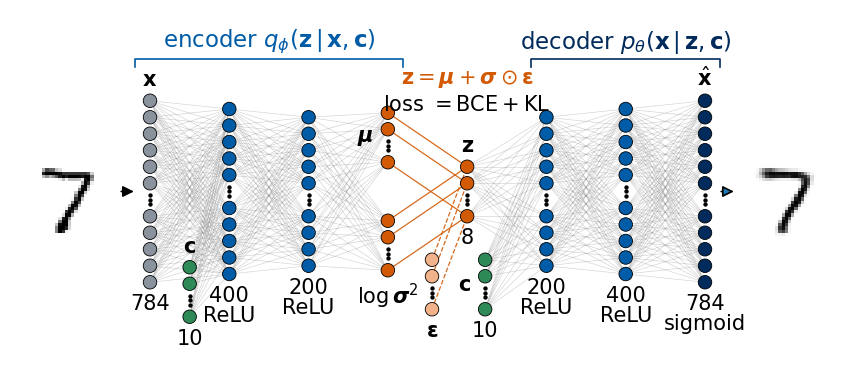

In [31]:
_m = VAE(8, cond=10, rngs=nnx.Rngs(0))
_mu, _lv = _m.encode(Xtr_d[:5], Ctr_d[:5])
assert Ctr_d.shape == (60000, 10) and _mu.shape == (5, 8)
assert _m.decode(_mu, Ctr_d[:5]).shape == (5, 784)
print("one-hot condition of the first training image (label", int(ytr[0]), "):", np.asarray(Ctr_d[0]).astype(int))

t0 = time.time()
print("cVAE, d = 8"); cvae, h_cvae = train(VAE(8, cond=10, rngs=nnx.Rngs(6)), vae_loss, (Xtr_d, Ctr_d), epochs=EPOCHS_VAE, seed=6)
print("cVAE, d = 2"); cvae2, _ = train(VAE(2, cond=10, rngs=nnx.Rngs(7)), vae_loss, (Xtr_d, Ctr_d), epochs=10, seed=7)
nums["cvae_train_seconds"] = time.time() - t0
Cte_d = jax.nn.one_hot(jnp.asarray(yte), 10)
_, aux = nnx.jit(vae_loss)(cvae, (Xte_d, Cte_d), jax.random.key(8))
nums["cvae8_test"] = {k: float(v) for k, v in aux.items()}
print("cVAE d = 8, test, per image:", {k: round(v, 1) for k, v in nums["cvae8_test"].items()})
cvae_enc = nnx.jit(lambda m, x, c: m.encode(x, c))
cvae_dec = nnx.jit(lambda m, z, c: jax.nn.sigmoid(m.decode(z, c)))

mu7, _ = cvae_enc(cvae, Xte_d[:1], Cte_d[:1])
with mpl.rc_context(SLIDE_RC):
    fig = draw_vae([784, 400, 200], 8, [200, 400, 784], cond=10, size=(5.5, 2.35), x_img=Xte[0].reshape(28, 28),
                   xhat_img=np.asarray(cvae_dec(cvae, mu7, Cte_d[:1]))[0].reshape(28, 28))
    save(fig, "gen_arch_cvae.png"); plt.show()

### 9.2 Generation at a chosen condition

A trained cVAE is sampled in the same two steps, with the condition held fixed: choose $\mathbf c$, draw $\mathbf z\sim p(\mathbf z|\mathbf c)=\mathcal N(0,I)$, and decode, $\mathbf x\sim p_\theta(\mathbf x|\mathbf z,\mathbf c)$ (we show the decoder mean, as before). The encoder is not used. Repeating this many times at the same $\mathbf c$ produces samples of $p_\theta(\mathbf x|\mathbf c)$, the model's distribution of all images with this label: here, all the ways of writing a 7. The roles of the two inputs are now separated by construction: $\mathbf c$ says which digit, $\mathbf z$ says how it is written. The two architectures are drawn below, in the same way as for the VAE in Section 6: in training the condition enters both the encoder and the decoder; in generation only the decoder is used, fed with a random $\mathbf z$ and the chosen $\mathbf c$.

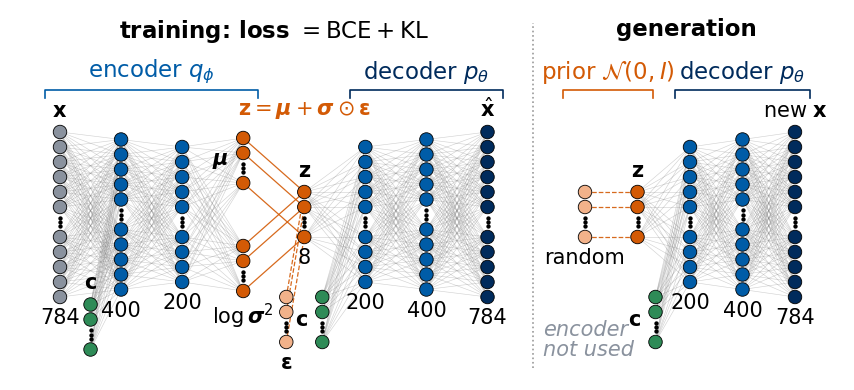

In [32]:
with mpl.rc_context(SLIDE_RC):
    fig = draw_vae_pair([784, 400, 200], 8, [200, 400, 784], cond=10, size=(5.5, 2.4))
    save(fig, "gen_cvae_train_gen.png"); plt.show()

The roles of the two inputs give the test of the next figure. Each row uses one condition $\mathbf c$, the digits 0 to 9. Each column uses one random $\mathbf z\sim\mathcal N(0,I)$, the same in every row.

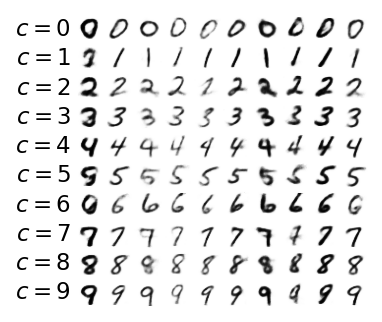

In [33]:
zc = jax.random.normal(jax.random.key(14), (10, 8))
rows = [np.asarray(cvae_dec(cvae, zc, jax.nn.one_hot(jnp.full(10, dgt), 10))) for dgt in range(10)]
show_grid(np.concatenate(rows), 10, 10, "gen_cvae_mnist.png", width=2.45, label_width=0.5,
          row_labels=[f"$c={d}$" for d in range(10)])

Along a column the digit changes and the style stays: slant, stroke width and size are carried by $\mathbf z$, the identity by $\mathbf c$. The same $\mathbf z$ with a different $\mathbf c$ is the same handwriting writing a different digit.

### Style transfer

The same separation lets us transfer the handwriting of a real digit to other digits. We encode a real test digit with its own label, $\boldsymbol\mu=\boldsymbol\mu_\phi(\mathbf x,\mathbf c_y)$, then decode this one $\mathbf z=\boldsymbol\mu$ with every condition $\mathbf c=0,\dots,9$: the same handwriting, all ten digits. In each row of the figure the real digit is on the left, followed by an empty cell and the ten decoded digits.

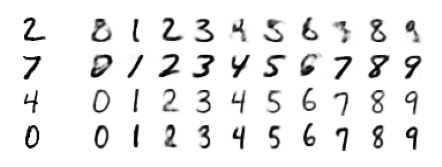

In [34]:
picks = [first_of(2), first_of(7, 3), first_of(4, 2), first_of(0, 5)]
rows = []
for k in picks:
    mu, _ = cvae_enc(cvae, Xte_d[k:k + 1], Cte_d[k:k + 1])
    out = np.asarray(cvae_dec(cvae, jnp.repeat(mu, 10, 0), jnp.eye(10)))
    rows.append(np.concatenate([Xte[k:k + 1], np.zeros((1, 784)), out]))
show_grid(np.concatenate(rows), len(picks), 12, "gen_cvae_style.png", width=2.75)

### Latent plane of the cVAE

If $\mathbf z$ really carries only style, the digit identity should no longer be visible in the latent plane. We draw the latent-grid figure of Sections 1 and 5.5 for the cVAE with $d=2$. The left panel shows the means $\boldsymbol\mu_\phi(\mathbf x,\mathbf c)$ of the test digits, each encoded with its own label and coloured by it, with the same quantile grid of $\mathcal N(0,1)$ as in Section 5.5. The right panel decodes every grid point with one fixed condition, $\mathbf c=$ one-hot(7). A simple number quantifies how much $\mathbf z$ knows about the digit: we predict the digit from the nearest class mean in the latent plane and report how often this prediction is correct, for the VAE and the cVAE.

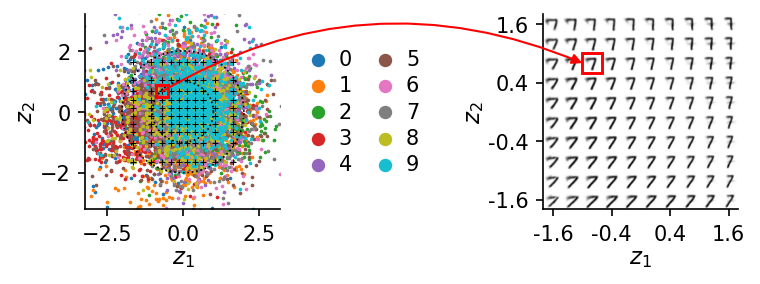

digit predicted from the nearest class mean in the latent plane: VAE 0.732, cVAE 0.180 (chance 0.1)


In [35]:
mu_c2 = in_chunks(lambda x, c: cvae_enc(cvae2, x, c)[0], Xte_d, Cte_d)
c7 = jax.nn.one_hot(7, 10)
latent_grid_figure(mu_c2, yte, lambda z: cvae_dec(cvae2, z, jnp.broadcast_to(c7, (z.shape[0], 10))), g_q, g_q,
                   highlight=(2, 7), name="gen_cvae_latent.png", prior_circles=True, lim=((-3.2, 3.2), (-3.2, 3.2)))

def centroid_acc(Z, y):
    """Fraction of points whose nearest class mean (in the latent plane) is the mean of their own class."""
    cent = np.stack([Z[y == d].mean(0) for d in range(10)])
    return float((((Z[:, None] - cent[None]) ** 2).sum(-1).argmin(1) == y).mean())
nums["latent_centroid_acc_vae2"], nums["latent_centroid_acc_cvae2"] = centroid_acc(mu2_te, yte), centroid_acc(mu_c2, yte)
print(f"digit predicted from the nearest class mean in the latent plane: VAE {nums['latent_centroid_acc_vae2']:.3f}, "
      f"cVAE {nums['latent_centroid_acc_cvae2']:.3f} (chance 0.1)")

In the VAE of Section 5 the digits form separate regions of the plane, and the nearest class mean predicts the digit correctly in 73% of the cases. In the cVAE all digits share the same disc, and the position of a code says little about which digit it is: the nearest-class-mean prediction is correct in 18% of the cases, close to the chance level of 10%. The latent plane of the cVAE is a map of style alone. Accordingly, every cell of the decoded grid is a 7, and moving across the grid changes only how the 7 is written: its slant, its width and the length of its bar.

### Conditions between two digits

The condition is an input like any other, so we may also give the decoder a $\mathbf c$ that never occurred in training. We fix three latent vectors and decode them with $\mathbf c(t)=(1-t)\,\mathbf e_4+t\,\mathbf e_9$, a straight line from the one-hot vector of a 4 to that of a 9 ($\mathbf e_k$ is the $k$-th unit vector); only the end points were ever seen. The right panel shows, for 1000 latent vectors $\mathbf z\sim\mathcal N(0,I)$, the fraction of decoded images that the classifier assigns to 4 and to 9 as a function of $t$.

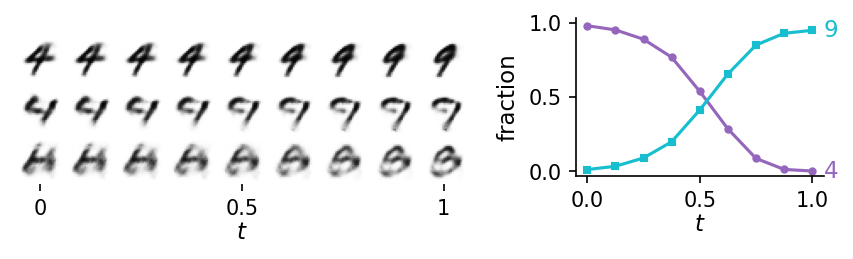

fraction classified as 9 along t: [0.01 0.03 0.09 0.2  0.41 0.65 0.85 0.93 0.95]


In [36]:
tt = np.linspace(0, 1, 9)
c_line = (1 - tt)[:, None] * np.eye(10)[4] + tt[:, None] * np.eye(10)[9]          # (9, 10) conditions from 4 to 9
z3 = jax.random.normal(jax.random.key(16), (3, 8))
rows = [np.asarray(cvae_dec(cvae, jnp.repeat(z3[r:r + 1], 9, 0), jnp.asarray(c_line, jnp.float32))) for r in range(3)]
z1000 = jax.random.normal(jax.random.key(17), (1000, 8))
frac4, frac9 = [], []
for c in c_line:
    lab = classify(cvae_dec(cvae, z1000, jnp.broadcast_to(jnp.asarray(c, jnp.float32), (1000, 10)))).argmax(1)
    frac4.append(float((lab == 4).mean())); frac9.append(float((lab == 9).mean()))
nums["cvae_mix_frac9"] = frac9
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 1.75))
    a = fig.add_axes([0.0, 0.2, 0.55, 0.65])
    a.imshow(mosaic(np.concatenate(rows), 3, 9), cmap="gray_r", vmin=0, vmax=1, extent=(-0.5, 8.5, 2.5, -0.5))
    a.set_yticks([]); a.set_xticks([0, 4, 8]); a.set_xticklabels(["0", "0.5", "1"]); a.set_xlabel("$t$", labelpad=1)
    for s_ in a.spines.values(): s_.set_visible(False)
    b = fig.add_axes([0.68, 0.27, 0.3, 0.6])
    b.plot(tt, frac4, "o-", color=cmap10(4), ms=3)
    b.plot(tt, frac9, "s-", color=cmap10(9), ms=3)
    b.text(1.05, frac4[-1], "4", color=cmap10(4), va="center", fontsize=11)        # direct labels at the line ends
    b.text(1.05, frac9[-1], "9", color=cmap10(9), va="center", fontsize=11)
    b.set_xlabel("$t$", labelpad=1); b.set_ylabel("fraction"); b.set_ylim(-0.03, 1.03)
    save(fig, "gen_cvae_mix.png"); plt.show()
print("fraction classified as 9 along t:", np.round(frac9, 2))

Along the line the images change continuously, with the style of each row kept; in the first row the open top of the 4 closes into the loop of a 9. The classifier switches from 4 to 9 around the middle of the line. A condition never seen in training is therefore not meaningless for the decoder: it interpolates between the conditions it was trained on. Whether such an interpolation is physically right cannot be decided by the network; for digits there is no "digit 6.5", but in Lab 025 the condition is a temperature or a point of a phase diagram, where intermediate values exist and the interpolated samples can be checked against Monte Carlo data.

### Confusion matrix of requested digits

The classifier of Section 8 now tests whether the cVAE draws what we ask for. For every requested digit $a$ we generate 1000 images with $\mathbf z\sim\mathcal N(0,I)$ and $\mathbf c=$ one-hot$(a)$, and let the classifier label them. The confusion matrix now has one row per requested digit $a$ and one column per digit $b$ assigned by the classifier,
$$C_{ab}=\frac{\#\{\text{samples generated with }\mathbf c=a\text{ assigned to }b\}}{1000}.$$

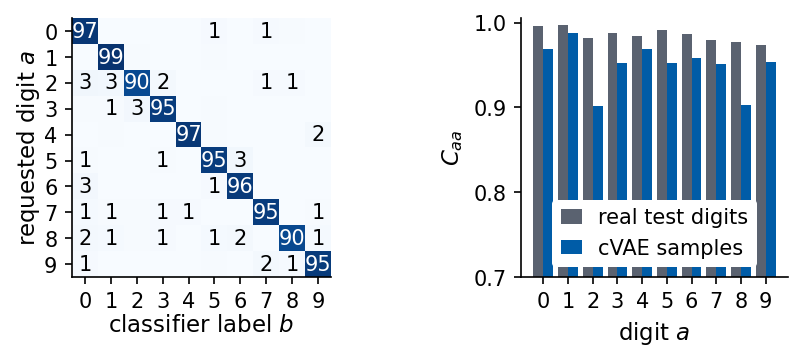

C_aa per requested digit: [0.969 0.988 0.902 0.952 0.969 0.952 0.958 0.951 0.903 0.954] | mean 0.9498
largest off-diagonal entry: requested 2, classified as 0: 0.032
fraction of cVAE samples with classifier confidence > 0.9: 0.875


In [37]:
N_PER = 1000
req = np.repeat(np.arange(10), N_PER)
z_req = jax.random.normal(jax.random.key(15), (10 * N_PER, 8))
cvae_samples = in_chunks(lambda z, c: cvae_dec(cvae, z, c), z_req, jax.nn.one_hot(jnp.asarray(req), 10))
P_cvae = classify(cvae_samples)
C_cvae = confusion(req, P_cvae.argmax(1))
nums["cvae_agreement_per_digit"] = np.diag(C_cvae).tolist()
nums["cvae_agreement_mean"] = float(np.trace(C_cvae) / 10)
nums["cvae_frac_confident_0.9"] = float((P_cvae.max(1) > 0.9).mean())
Cc = C_cvae.copy(); np.fill_diagonal(Cc, 0); i, j = np.unravel_index(np.argmax(Cc), Cc.shape)
nums["cvae_worst_confusion"] = [int(i), int(j), float(Cc[i, j])]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained", gridspec_kw=dict(width_ratios=[1.7, 1]))
    plot_confusion(axs[0], C_cvae, "requested digit $a$")
    axs[1].bar(np.arange(10) - 0.2, np.diag(mats["real"]), 0.4, color=UJGray, label="real test digits")
    axs[1].bar(np.arange(10) + 0.2, np.diag(C_cvae), 0.4, color=UJBlue, label="cVAE samples")
    axs[1].set_ylim(0.7, 1.005); axs[1].set_xticks(range(10)); axs[1].set_xlabel("digit $a$"); axs[1].set_ylabel("$C_{aa}$")
    axs[1].legend(loc="lower center", handlelength=1.0, frameon=True, facecolor="white", edgecolor="none", framealpha=1)
    save(fig, "gen_cvae_confusion.png"); plt.show()
print("C_aa per requested digit:", np.round(np.diag(C_cvae), 3), "| mean", round(nums["cvae_agreement_mean"], 4))
print(f"largest off-diagonal entry: requested {i}, classified as {j}: {Cc[i, j]:.3f}")
print(f"fraction of cVAE samples with classifier confidence > 0.9: {nums['cvae_frac_confident_0.9']:.3f}")

For every requested digit the large majority of the samples is classified as requested, by a classifier that never saw a synthetic image: the diagonal entries range from 0.902 (digit 2) to 0.988 (digit 1), with mean 0.950, and the largest confusion is a requested 2 classified as 0 in 3.2% of the samples. The same protocol carries over to physics in Lab 025. There the condition $\mathbf c$ is a temperature $T$ or a point $(g,T)$ of a phase diagram, samples are generated at a chosen $\mathbf c$, and the referees are networks trained on real Monte Carlo data, together with observables computed from the Hamiltonian itself.

Exercises:

1. Replace the one-hot condition by the single number $c=y/9$. Does the cVAE still generate the requested digits? Measure it with the confusion matrix, and decode the condition $c=6.5/9$.
2. Repeat the experiment with conditions between two digits for the pairs (1, 7) and (3, 8). Where does the classifier switch?

<hr/>
## Summary

An autoencoder compresses each image $\mathbf x$ into a point $\mathbf z=E(\mathbf x)$ of a latent space and decodes it back, but it learns no distribution of these points: its codes form islands, the space between them decodes to nonsense, and random latent vectors give no digits. A generative model must instead provide a distribution $p_\theta(\mathbf x)$ that can be sampled. The variational autoencoder builds it as a latent-variable model, $p_\theta(\mathbf x)=\int p(\mathbf z)\,p_\theta(\mathbf x|\mathbf z)\,d\mathbf z$, with a fixed prior $p(\mathbf z)=\mathcal N(0,I)$ and a network decoder $p_\theta(\mathbf x|\mathbf z)$, and trains it together with an encoder $q_\phi(\mathbf z|\mathbf x)$ that returns a Gaussian cloud of latent vectors for each image. The training objective is the evidence lower bound, $\mathrm{ELBO}=\mathbb E_{q_\phi}[\log p_\theta(\mathbf x|\mathbf z)]-\mathrm{KL}(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z))\le\log p_\theta(\mathbf x)$: the first term (minus the BCE for Bernoulli pixels) asks that points of each cloud decode back to their image, the second charges for information and pulls all clouds onto the prior, so that the prior region is filled with codes the decoder knows; the reparametrisation $\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon$ makes it trainable by backpropagation.

A trained VAE generates in two steps, $\mathbf z\sim\mathcal N(0,I)$ followed by the decoder. What is usually shown is the decoder mean, the pixel probabilities, which is smooth and blurry; a sample draws every pixel independently and is speckled, because all correlations between pixels must pass through $\mathbf z$. Generated digits are new combinations of learned features, as far from the training set as real unseen digits, and less clear on average than reconstructions, because the aggregate posterior $q_\phi(\mathbf z)$ of the encoded data does not fill the prior exactly. Straight lines in the latent space stay among the data, but single latent coordinates mix several properties of a digit, since the ELBO does not prefer any set of axes; a code with one property per coordinate, a disentangled code, is the goal of the $\beta$-VAE of Lab 026. A classifier trained on real data measures all this: confusion matrices, class frequencies and confidence of synthetic digits, always next to the same numbers for real digits. When the factor we want to control is labelled, the conditional VAE takes it as an input $\mathbf c$ of encoder and decoder: sampling at fixed $\mathbf c$ draws from $p_\theta(\mathbf x|\mathbf c)$, $\mathbf c$ selects the digit and $\mathbf z$ carries the style, and conditions between the trained ones are interpolated. Lab 025 applies this conditional generator to spin configurations, where the Hamiltonian provides a much stricter referee.